<a href="https://colab.research.google.com/github/Saimon0007/Financial-Inclusion-across-South-and-Southeast-Asia-after-COVID-19/blob/main/Thesis_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# -----------------------------------------------------------------------------
# 1. LOAD DATA
# -----------------------------------------------------------------------------
FILE_PATH = "/content/micro_world_139countries.csv"  # <-- change if needed

if FILE_PATH.endswith(".dta"):
    df_raw = pd.read_stata(FILE_PATH, convert_categoricals=False)
elif FILE_PATH.endswith(".csv"):
    df_raw = pd.read_csv(FILE_PATH, encoding='latin1')
else:
    raise ValueError("Set FILE_PATH to a .dta or .csv file.")

print(f"Loaded {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns.")
print(df_raw["economy"].nunique(), "economies in the file.")

# %%
# -----------------------------------------------------------------------------
# 2. SAFETY CHECK — confirm your target countries' exact 'economy' strings
#    before filtering. World Bank naming is usually the plain country name,
#    but a few economies use longer official forms (e.g. "Egypt, Arab Rep.",
#    "Lao PDR") — don't assume, check.
# -----------------------------------------------------------------------------
target_guess = ["India", "Bangladesh", "Pakistan", "Indonesia",
                 "Philippines", "Nepal", "Cambodia"]

all_economies = sorted(df_raw["economy"].dropna().unique())
print("Checking target country names against the file's actual 'economy' values:\n")
for c in target_guess:
    match = [e for e in all_economies if c.lower() in e.lower()]
    print(f"  {c:15s} -> found: {match if match else 'NO MATCH — inspect all_economies manually'}")

# If any show "NO MATCH", search all_economies yourself, e.g.:
# [e for e in all_economies if "nep" in e.lower()]

# %%


Loaded 143,887 rows and 128 columns.
139 economies in the file.
Checking target country names against the file's actual 'economy' values:

  India           -> found: ['India']
  Bangladesh      -> found: ['Bangladesh']
  Pakistan        -> found: ['Pakistan']
  Indonesia       -> found: ['Indonesia']
  Philippines     -> found: ['Philippines']
  Nepal           -> found: ['Nepal']
  Cambodia        -> found: ['Cambodia']


In [ ]:
#SUBSET TO TARGET COUNTRIES
#    Update TARGET_COUNTRIES below using the exact strings confirmed in step 2.
# -----------------------------------------------------------------------------
TARGET_COUNTRIES = ["India", "Bangladesh", "Pakistan", "Indonesia",
                     "Philippines", "Nepal", "Cambodia"]

df = df_raw[df_raw["economy"].isin(TARGET_COUNTRIES)].copy()
print(f"Subset to {len(TARGET_COUNTRIES)} target countries: {df.shape[0]:,} rows remain.")
print(df["economy"].value_counts())

Subset to 7 target countries: 9,064 rows remain.
economy
India          3000
Indonesia      1062
Pakistan       1002
Cambodia       1000
Bangladesh     1000
Nepal          1000
Philippines    1000
Name: count, dtype: int64


In [ ]:
# Save the subsetted dataframe to a CSV file
output_path = "/content/micro_world_subset.csv"
df.to_csv(output_path, index=False)
print(f"Subset successfully saved to {output_path}")

Subset successfully saved to /content/micro_world_subset.csv


In [ ]:

# --- Gender: recode 1/2 -> 1/0, female = 1 ---
df["female_d"] = np.where(df["female"] == 1, 1,
                    np.where(df["female"] == 2, 0, np.nan))

# --- Age and age-squared ---
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df["age2"] = df["age"] ** 2

# --- Education: keep as ordinal control, and also as dummies for flexibility ---
df["educ"] = pd.to_numeric(df["educ"], errors="coerce")
df["educ_secondary"] = (df["educ"] == 2).astype("Int64")
df["educ_tertiary"] = (df["educ"] == 3).astype("Int64")
# educ == 1 (primary or less) is the omitted/reference category

# --- Income quintile: keep as ordinal, and as dummies ---
df["inc_q"] = pd.to_numeric(df["inc_q"], errors="coerce")

# --- Employment: recode 1/2 -> 1/0, in workforce = 1 ---
df["emp_in_d"] = np.where(df["emp_in"] == 1, 1,
                    np.where(df["emp_in"] == 2, 0, np.nan))

# --- Rural/urban: recode 1/2 -> 1/0, rural = 1. Check coverage first. ---
if "urbanicity_f2f" in df.columns:
    df["rural_d"] = np.where(df["urbanicity_f2f"] == 1, 1,
                       np.where(df["urbanicity_f2f"] == 2, 0, np.nan))
    coverage = df.groupby("economy")["rural_d"].apply(lambda x: x.notna().mean())
    print("Rural/urban variable coverage by country (share non-missing):")
    print(coverage.round(3))
    print("\nPer the proposal's Section 3 risk note: for any country below ~0.5,")
    print("drop the rural/urban interaction for that country rather than the")
    print("whole analysis.")
else:
    print("WARNING: 'urbanicity_f2f' not found in this file — rural/urban")
    print("interactions (H2/step 5) will not be available for any country.")
    df["rural_d"] = np.nan

# --- Outcome variables: already 0/1 per codebook, just enforce numeric + labels ---
for var in ["account", "account_fin", "account_mob"]:
    if var not in df.columns:
        raise KeyError(f"Expected outcome variable '{var}' not found in the "
                        f"data. Check the codebook / file version.")
    df[var] = pd.to_numeric(df[var], errors="coerce")

# --- Survey weight ---
df["wgt"] = pd.to_numeric(df["wgt"], errors="coerce")

print("\nConstructed variables added: female_d, age2, educ_secondary, "
      "educ_tertiary, emp_in_d, rural_d")

Rural/urban variable coverage by country (share non-missing):
economy
Bangladesh     1.0
Cambodia       1.0
India          1.0
Indonesia      1.0
Nepal          1.0
Pakistan       1.0
Philippines    0.0
Name: rural_d, dtype: float64

Per the proposal's Section 3 risk note: for any country below ~0.5,
drop the rural/urban interaction for that country rather than the
whole analysis.

Constructed variables added: female_d, age2, educ_secondary, educ_tertiary, emp_in_d, rural_d


In [ ]:
# 5. MISSINGNESS CHECK
#    Report missingness for every variable this design depends on, by country,
#    so you catch a country-specific gap (e.g. rural/urban) before modeling.
# -----------------------------------------------------------------------------
core_vars = ["female_d", "age", "educ", "inc_q", "emp_in_d", "rural_d",
             "account", "account_fin", "account_mob", "wgt"]

missing_by_country = (
    df.groupby("economy")[core_vars]
      .apply(lambda x: x.isna().mean())
      .round(3)
)
print("Share missing, by country and variable:\n")
print(missing_by_country)

# Flag anything above a 5% missingness threshold for a closer look
threshold = 0.05
flagged = missing_by_country[(missing_by_country > threshold).any(axis=1)]
if not flagged.empty:
    print(f"\nCountries/variables exceeding {threshold:.0%} missing — inspect before modeling:")
    print(flagged)
else:
    print(f"\nNo variable exceeds {threshold:.0%} missing in any target country.")

# Drop rows missing the core outcome/predictor set (keep rural_d optional,
# since its absence is expected and handled per-country rather than case-wise)
required_for_model = ["female_d", "age", "educ", "inc_q", "emp_in_d",
                       "account", "account_fin", "account_mob", "wgt"]
n_before = len(df)
df_clean = df.dropna(subset=required_for_model).copy()
print(f"\nDropped {n_before - len(df_clean):,} rows missing a required variable "
      f"({(n_before - len(df_clean)) / n_before:.1%} of the target-country sample).")
print(f"Analysis sample: {len(df_clean):,} respondents across "
      f"{df_clean['economy'].nunique()} countries.")

Share missing, by country and variable:

             female_d    age  educ  inc_q  emp_in_d  rural_d  account  \
economy                                                                 
Bangladesh        0.0  0.000   0.0    0.0       0.0      0.0      0.0   
Cambodia          0.0  0.000   0.0    0.0       0.0      0.0      0.0   
India             0.0  0.000   0.0    0.0       0.0      0.0      0.0   
Indonesia         0.0  0.000   0.0    0.0       0.0      0.0      0.0   
Nepal             0.0  0.000   0.0    0.0       0.0      0.0      0.0   
Pakistan          0.0  0.001   0.0    0.0       0.0      0.0      0.0   
Philippines       0.0  0.001   0.0    0.0       0.0      1.0      0.0   

             account_fin  account_mob  wgt  
economy                                     
Bangladesh           0.0          0.0  0.0  
Cambodia             0.0          0.0  0.0  
India                0.0          0.0  0.0  
Indonesia            0.0          0.0  0.0  
Nepal                0.0       

**Check before running the analysis scripts: education codes.** The next cell lists the values of `educ` in the seven economies. The model builds dummies for `educ == 2` and `educ == 3`, so any other value (for example a don't-know or refused code, if the file has one) falls in the primary-or-less reference group. If the count outside 1-3 is zero, nothing changes. If it is not zero, state the number in Section 3, or set those values to missing in the cleaning cell and rerun the analysis scripts.

In [ ]:
# Diagnostic only: does educ contain values other than 1, 2, 3 in the seven economies?
print(df_raw.loc[df_raw["economy"].isin(TARGET_COUNTRIES), "educ"].value_counts(dropna=False).sort_index())
odd = df_clean[~df_clean["educ"].isin([1, 2, 3])]
print("\nRespondents in the analysis sample with educ outside 1-3:", len(odd))
print(odd.groupby("economy").size() if len(odd) else "None.")


educ
1    4664
2    3586
3     793
4       4
5      17
Name: count, dtype: int64

Respondents in the analysis sample with educ outside 1-3: 21
economy
Bangladesh     1
Cambodia       9
India         11
dtype: int64


In [ ]:
df_clean.groupby(["economy","female_d"])["account_mob"].sum().unstack()

female_d,0.0,1.0
economy,,
Bangladesh,159.0,120.0
Cambodia,19.0,28.0
India,286.0,78.0
Indonesia,42.0,49.0
Nepal,45.0,22.0
Pakistan,73.0,17.0
Philippines,147.0,153.0


In [ ]:
# for every country-level and descriptive step above; use 'wgt_pooled'
# only in the Day 10-11 pooled model, and report the population-weighted
# version (raw 'wgt') as a robustness check per Section 4, step 7.
# -----------------------------------------------------------------------------
df_clean["wgt_pooled"] = (
    df_clean.groupby("economy")["wgt"]
    .transform(lambda w: w / w.sum())  # each country's weights now sum to 1
)
# Now every country contributes equally to a pooled regression using
# wgt_pooled, independent of both raw N and national population size.

check = df_clean.groupby("economy")["wgt_pooled"].sum().round(6)
print("Sanity check — each country's pooled weight should sum to 1.0:")
print(check)


Sanity check — each country's pooled weight should sum to 1.0:
economy
Bangladesh     1.0
Cambodia       1.0
India          1.0
Indonesia      1.0
Nepal          1.0
Pakistan       1.0
Philippines    1.0
Name: wgt_pooled, dtype: float64


In [ ]:
df_clean.to_csv("/content/findex_7country_clean.csv", index=False)
print("Saved cleaned dataset to /content/findex_7country_clean.csv")

Saved cleaned dataset to /content/findex_7country_clean.csv


In [ ]:
# DAY 6 — DESCRIPTIVE STATISTICS: WEIGHTED GENDER GAP BY COUNTRY, BY CHANNEL
# =============================================================================

# %%
def weighted_mean(x, w):
    """Survey-weighted mean, ignoring rows where the value or weight is NaN."""
    mask = x.notna() & w.notna()
    if mask.sum() == 0:
        return np.nan
    return np.average(x[mask], weights=w[mask])

def weighted_gap_table(data, outcome_vars, group_var="economy"):
    """
    For each country, compute the survey-weighted mean of each outcome
    separately for women and men, and the gap (men - women, in percentage
    points). This is the raw/unadjusted gap described in Section 4, step 1
    of the proposal — not yet the marginal-effects version from step 2.
    """
    rows = []
    for country, g in data.groupby(group_var):
        row = {"economy": country, "n": len(g)}
        for var in outcome_vars:
            w_female = weighted_mean(g.loc[g["female_d"] == 1, var],
                                      g.loc[g["female_d"] == 1, "wgt"])
            w_male = weighted_mean(g.loc[g["female_d"] == 0, var],
                                    g.loc[g["female_d"] == 0, "wgt"])
            row[f"{var}_female"] = w_female
            row[f"{var}_male"] = w_male
            row[f"{var}_gap_pp"] = (w_male - w_female) * 100
        rows.append(row)
    return pd.DataFrame(rows).sort_values("economy").reset_index(drop=True)

outcome_vars = ["account", "account_fin", "account_mob"]
gap_table = weighted_gap_table(df_clean, outcome_vars)

pd.set_option("display.float_format", lambda x: f"{x:.3f}")
print("Survey-weighted gender gap in account ownership, by country and channel:\n")
print(gap_table[["economy", "n"] +
                 [c for v in outcome_vars for c in
                  (f"{v}_female", f"{v}_male", f"{v}_gap_pp")]])

Survey-weighted gender gap in account ownership, by country and channel:

       economy     n  account_female  account_male  account_gap_pp  \
0   Bangladesh  1000           0.435         0.629          19.406   
1     Cambodia  1000           0.325         0.344           1.888   
2        India  3000           0.776         0.775          -0.045   
3    Indonesia  1062           0.523         0.512          -1.123   
4        Nepal  1000           0.499         0.586           8.707   
5     Pakistan  1001           0.135         0.282          14.631   
6  Philippines   999           0.474         0.553           7.854   

   account_fin_female  account_fin_male  account_fin_gap_pp  \
0               0.306             0.453              14.758   
1               0.313             0.341               2.821   
2               0.775             0.771              -0.317   
3               0.517             0.493              -2.384   
4               0.497             0.563           

In [ ]:
gap_table.to_csv("/content/weighted_gender_gap_by_country.csv", index=False)
print("\nSaved to /content/weighted_gender_gap_by_country.csv")


Saved to /content/weighted_gender_gap_by_country.csv


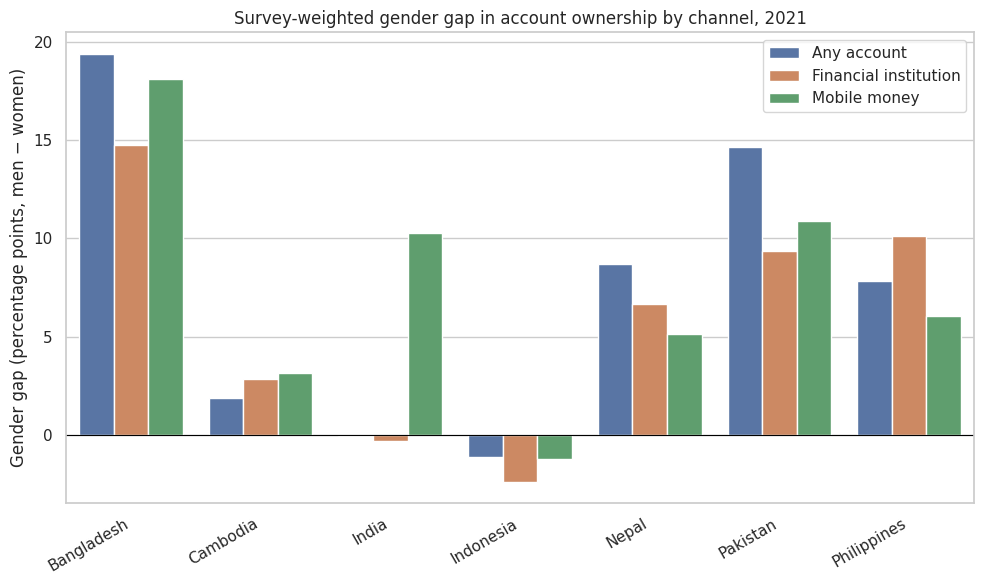

In [ ]:
# EXPLORATORY CHART 1 — Grouped bar chart: gender gap (pp) by country, by channel
plot_df = gap_table.melt(
    id_vars="economy",
    value_vars=[f"{v}_gap_pp" for v in outcome_vars],
    var_name="channel", value_name="gap_pp"
)
plot_df["channel"] = plot_df["channel"].str.replace("_gap_pp", "", regex=False)
plot_df["channel"] = plot_df["channel"].map({
    "account": "Any account",
    "account_fin": "Financial institution",
    "account_mob": "Mobile money"
})

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_df, x="economy", y="gap_pp", hue="channel")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Gender gap (percentage points, men − women)")
plt.xlabel("")
plt.title("Survey-weighted gender gap in account ownership by channel, 2021")
plt.xticks(rotation=30, ha="right")
plt.legend(title="")
plt.tight_layout()
plt.savefig("/content/gender_gap_by_country_channel.png", dpi=150)
plt.show()

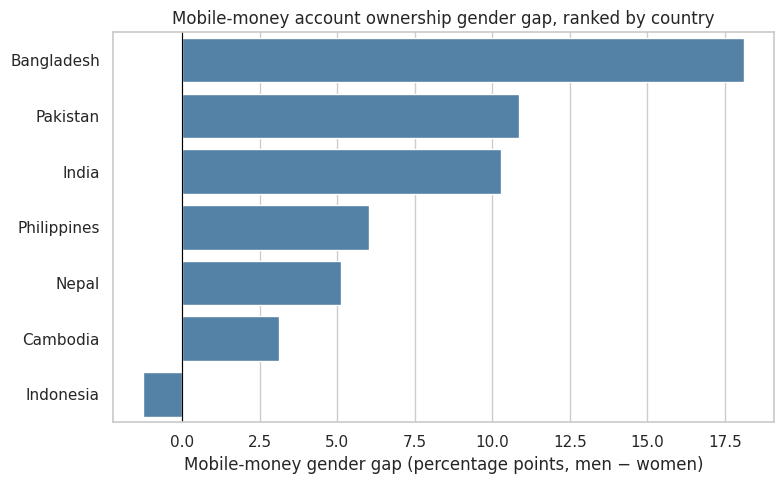

In [ ]:
# EXPLORATORY CHART 2 — Country ranking on the mobile-money channel specifically
#    (the channel this paper's core comparison hinges on)
mob_sorted = gap_table.sort_values("account_mob_gap_pp", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=mob_sorted, x="account_mob_gap_pp", y="economy",
            color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Mobile-money gender gap (percentage points, men − women)")
plt.ylabel("")
plt.title("Mobile-money account ownership gender gap, ranked by country")
plt.tight_layout()
plt.savefig("/content/mobile_money_gap_ranked.png", dpi=150)
plt.show()

In [ ]:
# EXPLORATORY CHART 3 — Sample size sanity check (per-country n, split by gender)
#    Cheap check before doing anything statistical: flag any country/gender
#    cell that's too thin to support reliable marginal effects later.
n_table = (
    df_clean.groupby(["economy", "female_d"])
    .size()
    .unstack()
    .rename(columns={0: "n_male", 1: "n_female"})
)
n_table["total"] = n_table.sum(axis=1)
print("Sample size by country and gender:\n")
print(n_table)

if (n_table[["n_male", "n_female"]] < 200).any(axis=None):
    print("\nWARNING: at least one country-gender cell has fewer than 200 "
          "respondents — country-level marginal effects for that cell "
          "(Section 4, step 2) may be imprecise. Check before proceeding.")


Sample size by country and gender:

female_d     n_male  n_female  total
economy                             
Bangladesh      412       588   1000
Cambodia        352       648   1000
India          1618      1382   3000
Indonesia       460       602   1062
Nepal           454       546   1000
Pakistan        499       502   1001
Philippines     426       573    999


In [ ]:
# =============================================================================
# Global Findex 2021 — Day 19: Is the mobile-money gender gap really different
# from the bank-account gender gap?  (cross-channel equality test)
#
# WHY: The paper's central claim is that the gap is concentrated in mobile
# money (significant in 5/7 countries) while the composite/bank measure is
# significant in fewer. That comparison rests on SEPARATE models, one
# "significant" and one "not". The difference between "significant" and "not
# significant" is not itself statistically significant (Gelman & Stern, 2006,
# The American Statistician 60(4):328-331). This script tests the difference
# directly, on the SAME people.
#
# DESIGN (per country, then pooled)
#   Sample: respondents with non-missing account_fin, account_mob, weights,
#   female_d and all controls, so both channels use IDENTICAL people.
#   Stack long: one row per person per channel (bank = account_fin,
#   mobile = account_mob), mob = 1 for the mobile rows.
#
#   Test 1 (index scale, probit, person-clustered SEs):
#       y = b0 + b1*female + b2*mob + b3*female*mob + X*g + (X*mob)*d
#     Controls fully interacted with channel, so this is equivalent to two
#     separate probits estimated jointly; b3 = difference between the female
#     coefficients of the mobile and bank equations. H0: b3 = 0.
#     Clustering by person handles the same person appearing twice.
#     (Sign: female coef is NEGATIVE when women are less likely, so a
#     NEGATIVE b3 means a LARGER female disadvantage in mobile money.)
#
#   Test 2 (probability scale, person bootstrap):
#       diff = AME_gap_mobile - AME_gap_bank, each AME = male minus female
#     as in every earlier script. POSITIVE diff = the mobile gap is larger.
#     Persons are resampled uniformly (not weight-proportional) and each
#     resample is fit with the survey weights. CI and p from the bootstrap.
#     This sidesteps the Ai & Norton (2003, Economics Letters 80(1):123-129)
#     point that a probit interaction COEFFICIENT is not the interaction
#     effect on the probability.
#
#   BH-FDR across countries within each test. A "pooled" row stacks all
#   countries with country fixed effects fully interacted with channel and a
#   single female*mob term, as the average-across-countries summary.
#
# Not accounted for: survey strata/clusters (not in the cleaned file).
# Input: findex_7country_clean.csv (Day 4-6).
# =============================================================================

# %%
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

np.random.seed(42)

DATA_PATH = os.environ.get("FINDEX_CSV", "/content/findex_7country_clean.csv")
OUT_DIR = os.environ.get("FINDEX_OUT", "/content")
N_BOOT = int(os.environ.get("FINDEX_NBOOT", 800))
LINK = sm.families.links.Probit()
FDR_Q = 0.05

# %%
# -----------------------------------------------------------------------------
# 1. LOAD
# -----------------------------------------------------------------------------
df = pd.read_csv(DATA_PATH)
df["inc_q"] = df["inc_q"].astype(int)
inc_dummies = pd.get_dummies(df["inc_q"], prefix="inc_q", drop_first=True).astype(float)
df = pd.concat([df, inc_dummies], axis=1)
inc_q_cols = list(inc_dummies.columns)
controls = ["age", "age2", "educ_secondary", "educ_tertiary", "emp_in_d"] + inc_q_cols

need = ["account_fin", "account_mob", "female_d", "wgt"] + controls
n0 = len(df)
df = df.dropna(subset=need).copy().reset_index(drop=True)
df["pid"] = np.arange(len(df))
countries = sorted(df["economy"].unique())
print(f"Loaded {n0:,} rows; {len(df):,} complete cases for BOTH channels and all controls.")
print("Countries:", countries)

# %%
# -----------------------------------------------------------------------------
# 2. HELPERS
# -----------------------------------------------------------------------------
def stack(d):
    """Long format: bank rows (mob=0, y=account_fin) and mobile rows (mob=1)."""
    b = d.copy(); b["mob"] = 0.0; b["y"] = b["account_fin"].astype(float)
    m = d.copy(); m["mob"] = 1.0; m["y"] = m["account_mob"].astype(float)
    return pd.concat([b, m], ignore_index=True)

def design(long, extra_cols=None, interact_controls=True):
    X = pd.DataFrame(index=long.index)
    X["female_d"] = long["female_d"].astype(float)
    X["mob"] = long["mob"]
    X["female_x_mob"] = X["female_d"] * X["mob"]
    for c in controls:
        X[c] = long[c].astype(float)
        if interact_controls:
            X[c + "_x_mob"] = long[c].astype(float) * long["mob"]
    if extra_cols is not None:
        for c in extra_cols:
            X[c] = long[c].astype(float)
    return sm.add_constant(X, has_constant="add")

def index_scale_test(d, interact_controls=True, fe_cols=None):
    long = stack(d)
    extra = None
    if fe_cols:
        extra = []
        for c in fe_cols:
            long[c + "_x_mob"] = long[c] * long["mob"]
            extra += [c, c + "_x_mob"]
    X = design(long, extra_cols=extra, interact_controls=interact_controls)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = sm.GLM(long["y"], X, family=sm.families.Binomial(link=LINK),
                     freq_weights=long["wgt"].astype(float)).fit(
                         cov_type="cluster", cov_kwds={"groups": long["pid"].values})
    b, se = fit.params["female_x_mob"], fit.bse["female_x_mob"]
    z = b / se
    return {"b_female_x_mob": b, "se": se, "z": z, "p": 2 * stats.norm.sf(abs(z)),
            "b_female_bank": fit.params["female_d"],
            "b_female_mobile": fit.params["female_d"] + b}

def ame_one(d, outcome):
    X = sm.add_constant(d[["female_d"] + controls].astype(float), has_constant="add")
    y = d[outcome].astype(float); w = d["wgt"].astype(float)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = sm.GLM(y, X, family=sm.families.Binomial(link=LINK), freq_weights=w).fit()
    X1 = X.copy(); X1["female_d"] = 1.0
    X0 = X.copy(); X0["female_d"] = 0.0
    return np.average(fit.predict(X0) - fit.predict(X1), weights=w)

def prob_scale_test(d, n_boot=N_BOOT):
    ame_bank = ame_one(d, "account_fin")
    ame_mob = ame_one(d, "account_mob")
    diff = ame_mob - ame_bank
    n = len(d); idx_all = np.arange(n); vals = []
    for _ in range(n_boot):
        bs = d.iloc[np.random.choice(idx_all, size=n, replace=True)]
        if bs["female_d"].nunique() < 2:
            continue
        try:
            vals.append(ame_one(bs, "account_mob") - ame_one(bs, "account_fin"))
        except Exception:
            continue
    if len(vals) < 50:
        return dict(ame_bank=ame_bank, ame_mobile=ame_mob, diff=diff, boot_se=np.nan,
                    ci_low=np.nan, ci_high=np.nan, p=np.nan, n_boot_ok=len(vals))
    se = np.std(vals, ddof=1)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return dict(ame_bank=ame_bank, ame_mobile=ame_mob, diff=diff, boot_se=se,
                ci_low=lo, ci_high=hi, p=2 * stats.norm.sf(abs(diff / se)) if se > 0 else np.nan,
                n_boot_ok=len(vals))

def bh_fdr(p):
    p = np.asarray(p, dtype=float)
    out = np.full_like(p, np.nan); ok = ~np.isnan(p); pv = p[ok]; m = len(pv)
    order = np.argsort(pv)
    ranked = pv[order] * m / np.arange(1, m + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adj = np.empty(m); adj[order] = np.minimum(ranked, 1.0); out[ok] = adj
    return out

# %%
# -----------------------------------------------------------------------------
# 3. PER-COUNTRY TESTS
# -----------------------------------------------------------------------------
rows, failed = [], []
for c in countries:
    sub = df[df["economy"] == c].copy()
    print(f"Country: {c}  (n = {len(sub):,})")
    try:
        t1 = index_scale_test(sub, interact_controls=True)
        t1a = index_scale_test(sub, interact_controls=False)   # common-slope variant
        t2 = prob_scale_test(sub)
    except Exception as e:
        print(f"  FAILED: {e}")
        failed.append((c, str(e)))
        continue
    rows.append({"economy": c, "n": len(sub),
                 "ame_gap_bank": t2["ame_bank"], "ame_gap_mobile": t2["ame_mobile"],
                 "diff_mobile_minus_bank": t2["diff"], "boot_se": t2["boot_se"],
                 "ci_low": t2["ci_low"], "ci_high": t2["ci_high"], "p_prob": t2["p"],
                 "b_female_bank": t1["b_female_bank"], "b_female_mobile": t1["b_female_mobile"],
                 "b_female_x_mob": t1["b_female_x_mob"], "se_index": t1["se"],
                 "p_index": t1["p"], "p_index_commonslope": t1a["p"]})

res = pd.DataFrame(rows)
if res.empty:
    raise SystemExit("No country models completed.")
res["p_prob_fdr"] = bh_fdr(res["p_prob"].values)
res["p_index_fdr"] = bh_fdr(res["p_index"].values)
res["sig_prob_fdr"] = res["p_prob_fdr"] < FDR_Q
res["sig_index_fdr"] = res["p_index_fdr"] < FDR_Q

# %%
# -----------------------------------------------------------------------------
# 4. POOLED (country FE fully interacted with channel; one female*mob term)
# -----------------------------------------------------------------------------
fe = pd.get_dummies(df["economy"], prefix="fe", drop_first=True).astype(float)
dfp = pd.concat([df, fe], axis=1)
fe_cols = list(fe.columns)
pooled = index_scale_test(dfp, interact_controls=True, fe_cols=fe_cols)
print("\nPOOLED (country FE x channel, controls x channel):")
print(f"  female x mobile coef = {pooled['b_female_x_mob']:.4f}  (se {pooled['se']:.4f}, "
      f"p = {pooled['p']:.4g})")
print("  negative = larger female disadvantage in mobile money than in bank accounts")

# %%
# -----------------------------------------------------------------------------
# 5. OUTPUT
# -----------------------------------------------------------------------------
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.width", 220)
print("\n" + "=" * 90)
print("CROSS-CHANNEL EQUALITY TEST BY COUNTRY")
print("  diff = AME gap(mobile) - AME gap(bank), male minus female; positive = mobile gap larger")
print("  index-scale: negative b_female_x_mob = larger female disadvantage in mobile")
print("=" * 90)
print(res[["economy", "n", "ame_gap_bank", "ame_gap_mobile", "diff_mobile_minus_bank",
           "ci_low", "ci_high", "p_prob", "p_prob_fdr", "b_female_x_mob",
           "p_index", "p_index_fdr", "p_index_commonslope"]].to_string(index=False))

print("\nCountries where the mobile gap is significantly LARGER than the bank gap "
      "(probability scale, FDR):")
big = res[(res["sig_prob_fdr"]) & (res["diff_mobile_minus_bank"] > 0)]
print(big[["economy", "diff_mobile_minus_bank", "p_prob_fdr"]].to_string(index=False)
      if len(big) else "  none")

print("\nCountries where the two gaps differ significantly in the OTHER direction "
      "(bank gap larger):")
rev = res[(res["sig_prob_fdr"]) & (res["diff_mobile_minus_bank"] < 0)]
print(rev[["economy", "diff_mobile_minus_bank", "p_prob_fdr"]].to_string(index=False)
      if len(rev) else "  none")

agree = (res["sig_prob_fdr"] == res["sig_index_fdr"]).mean()
print(f"\nIndex-scale and probability-scale tests agree on FDR significance in {agree:.0%} of countries.")
print("If they disagree for a country, report both and say which scale each speaks to.")

n_prob = len(big)
n_idx = int(((res["sig_index_fdr"]) & (res["b_female_x_mob"] < 0)).sum())
print("\n" + "-" * 90)
print(f"READ-OUT: mobile gap significantly larger than bank gap (after FDR) in "
      f"{n_prob} of {len(res)} countries on the PROBABILITY scale, and in {n_idx} of "
      f"{len(res)} on the INDEX (probit coefficient) scale.")
print("The two scales answer different questions and the probability-scale test has less power "
      "(bounded outcomes compress differences). Report both. A claim like 'the mobile gap is larger "
      "than the bank gap' needs at least one of them; say which one.")
print("-" * 90)

res["n_boot_requested"] = N_BOOT
res.to_csv(os.path.join(OUT_DIR, "day19_channel_gap_equality.csv"), index=False)
print(f"\nSaved {os.path.join(OUT_DIR, 'day19_channel_gap_equality.csv')}")
if failed:
    print("Failed:", failed)

Loaded 9,062 rows; 9,062 complete cases for BOTH channels and all controls.
Countries: ['Bangladesh', 'Cambodia', 'India', 'Indonesia', 'Nepal', 'Pakistan', 'Philippines']
Country: Bangladesh  (n = 1,000)
Country: Cambodia  (n = 1,000)
Country: India  (n = 3,000)
Country: Indonesia  (n = 1,062)
Country: Nepal  (n = 1,000)
Country: Pakistan  (n = 1,001)
Country: Philippines  (n = 999)

POOLED (country FE x channel, controls x channel):
  female x mobile coef = -0.3020  (se 0.0558, p = 6.069e-08)
  negative = larger female disadvantage in mobile money than in bank accounts

CROSS-CHANNEL EQUALITY TEST BY COUNTRY
  diff = AME gap(mobile) - AME gap(bank), male minus female; positive = mobile gap larger
  index-scale: negative b_female_x_mob = larger female disadvantage in mobile
    economy    n  ame_gap_bank  ame_gap_mobile  diff_mobile_minus_bank  ci_low  ci_high  p_prob  p_prob_fdr  b_female_x_mob  p_index  p_index_fdr  p_index_commonslope
 Bangladesh 1000        0.1172          0.1375 

In [ ]:
# =============================================================================
# Global Findex 2021 — Day 20: Closing robustness pass
#
# PURPOSE: remove the avoidable ways the main results can be attacked.
#
# WHAT WAS CHECKED BEFORE WRITING THIS (numerically, on test data):
#   * statsmodels GLM with freq_weights + cov_type "HC0"/"HC1" (and the default
#     covariance) treats weights as REPLICATED OBSERVATIONS. Its standard errors
#     were about half of the correct survey-weight (pweight) sandwich:
#         freq_weights default/HC0/HC1 SE : 0.030
#         manual pweight sandwich         : 0.057
#         uniform person bootstrap        : 0.060
#   * cov_type="cluster" with groups = one cluster per row reproduces the
#     pweight sandwich (0.057), so it is safe. The Day 19 stacked test (clustered
#     by person) is therefore fine. Day 10-11 / 15-16 Wald p-values that used the
#     default GLM covariance are NOT safe, and a likelihood-ratio test is not
#     valid under survey weights at all. This script therefore uses:
#       - uniform person bootstrap for AME standard errors, and
#       - cluster-by-row robust covariance for coefficient Wald tests.
#   * The older bootstrap (probability-proportional resampling + weighted fit)
#     double-counts the weights; this script resamples uniformly.
#
# WHAT THIS SCRIPT DOES
#   1. Sample accounting: raw n, complete cases, share lost, Kish design effect
#      from the weights and the effective sample size, per country.
#   2. Main spec re-estimated with corrected inference: weighted probit AME
#      (male minus female), bootstrap SE/CI/p, BH-FDR over all 21 tests.
#   3. Specification grid for every country x outcome:
#        S1 probit, full controls (main)      S4 probit, age + education only
#        S2 logit,  full controls             S5 probit, no controls (raw gap)
#        S3 linear probability (WLS, HC1)     S6 probit, full controls, UNweighted
#      S4 matters because income and employment may be mediators of a gender gap.
#      A result is called ROBUST if it is FDR-significant in S1, has the same sign
#      in all six specs, and p < .05 in at least four of S2-S6.
#   4. Power: minimum detectable AME (80% power, alpha .05, = 2.8 x SE).
#   5. Coefficient stability: female coefficient (LPM) without vs with controls.
#      DESCRIPTIVE only; it is not a bound on unobserved confounding.
#   6. Pooled cross-channel test (stacked, as Day 19): all countries, then
#      leave-one-country-out, then a joint test that the female x mobile term
#      differs across countries.
#
# NOT FIXABLE HERE: the cleaned file has no strata/PSU, so sampling-design
# clustering is not modelled; 2021 cross-section => associations only.
#
# Input: findex_7country_clean.csv (Day 4-6). Run time: scales with N_BOOT.
# =============================================================================

# %%
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

np.random.seed(42)
DATA_PATH = os.environ.get("FINDEX_CSV", "/content/findex_7country_clean.csv")
OUT_DIR = os.environ.get("FINDEX_OUT", "/content")
N_BOOT = int(os.environ.get("FINDEX_NBOOT", 800))
FDR_Q = 0.05
PROBIT = sm.families.links.Probit()
LOGIT = sm.families.links.Logit()
outcomes = ["account", "account_fin", "account_mob"]

# %%
# -----------------------------------------------------------------------------
# 1. LOAD + SAMPLE ACCOUNTING
# -----------------------------------------------------------------------------
raw = pd.read_csv(DATA_PATH)
raw["inc_q"] = raw["inc_q"].astype("Int64")
inc_d = pd.get_dummies(raw["inc_q"], prefix="inc_q", drop_first=True).astype(float)
raw = pd.concat([raw, inc_d], axis=1)
inc_cols = list(inc_d.columns)
FULL = ["age", "age2", "educ_secondary", "educ_tertiary", "emp_in_d"] + inc_cols
MIN = ["age", "age2", "educ_secondary", "educ_tertiary"]
countries = sorted(raw["economy"].unique())

need_full = ["female_d", "wgt"] + outcomes + FULL
need_min = ["female_d", "wgt"] + outcomes + MIN
rows = []
for c in countries:
    s = raw[raw["economy"] == c]
    cf = s.dropna(subset=need_full); cm = s.dropna(subset=need_min)
    w = cf["wgt"].astype(float)
    deff = len(cf) * (w ** 2).sum() / (w.sum() ** 2)
    rows.append({"economy": c, "n_raw": len(s), "n_complete_full": len(cf),
                 "pct_lost_full": 100 * (1 - len(cf) / len(s)),
                 "n_complete_minimal": len(cm),
                 "kish_deff_weights": deff, "n_effective": len(cf) / deff})
acct = pd.DataFrame(rows)
pd.set_option("display.width", 220)
print("=" * 90 + "\nSAMPLE ACCOUNTING (Kish deff reflects weighting only; strata/PSU unavailable)\n" + "=" * 90)
print(acct.round(2).to_string(index=False))
acct.to_csv(os.path.join(OUT_DIR, "day20_sample_accounting.csv"), index=False)

# Analysis sample: complete on FULL (so every spec uses the same people)
df = raw.dropna(subset=need_full).copy().reset_index(drop=True)
for c in ["female_d"] + outcomes:
    df[c] = df[c].astype(float)

# %%
# -----------------------------------------------------------------------------
# 2. ESTIMATORS
# -----------------------------------------------------------------------------
def _design(d, controls):
    return sm.add_constant(d[["female_d"] + controls].astype(float), has_constant="add")

def ame_glm(d, outcome, controls, link, weighted=True):
    X = _design(d, controls); y = d[outcome].astype(float)
    w = d["wgt"].astype(float) if weighted else np.ones(len(d))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = sm.GLM(y, X, family=sm.families.Binomial(link=link), freq_weights=w).fit()
    X1 = X.copy(); X1["female_d"] = 1.0
    X0 = X.copy(); X0["female_d"] = 0.0
    return np.average(fit.predict(X0) - fit.predict(X1), weights=w)   # male - female

def lpm(d, outcome, controls):
    X = _design(d, controls); y = d[outcome].astype(float); w = d["wgt"].astype(float)
    fit = sm.WLS(y, X, weights=w).fit(cov_type="HC1")   # pweight sandwich (verified logic)
    b = -fit.params["female_d"]                          # male - female
    se = fit.bse["female_d"]
    return b, se, 2 * stats.norm.sf(abs(b / se)), fit.rsquared

def boot(d, fn, n_boot=N_BOOT):
    n = len(d); vals = []; ar = np.arange(n)
    for _ in range(n_boot):
        bs = d.iloc[np.random.choice(ar, size=n, replace=True)]   # UNIFORM resample
        if bs["female_d"].nunique() < 2:
            continue
        try:
            vals.append(fn(bs))
        except Exception:
            continue
    if len(vals) < 50:
        return np.nan, np.nan
    return np.std(vals, ddof=1), len(vals)

def pval(est, se):
    return 2 * stats.norm.sf(abs(est / se)) if se and np.isfinite(se) and se > 0 else np.nan

def bh_fdr(p):
    p = np.asarray(p, dtype=float); out = np.full_like(p, np.nan)
    ok = ~np.isnan(p); pv = p[ok]; m = len(pv); o = np.argsort(pv)
    r = np.minimum.accumulate((pv[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    a = np.empty(m); a[o] = np.minimum(r, 1.0); out[ok] = a
    return out

SPECS = {
    "S1_probit_full": dict(controls=FULL, link=PROBIT, weighted=True),
    "S2_logit_full": dict(controls=FULL, link=LOGIT, weighted=True),
    "S4_probit_age_educ": dict(controls=MIN, link=PROBIT, weighted=True),
    "S5_probit_nocontrols": dict(controls=[], link=PROBIT, weighted=True),
    "S6_probit_full_unweighted": dict(controls=FULL, link=PROBIT, weighted=False),
}

# %%
# -----------------------------------------------------------------------------
# 3. SPECIFICATION GRID
# -----------------------------------------------------------------------------
recs = []
for c in countries:
    sub = df[df["economy"] == c].copy()
    for o in outcomes:
        print(f"{c} — {o}")
        row = {"economy": c, "outcome": o, "n": len(sub)}
        for name, sp in SPECS.items():
            try:
                est = ame_glm(sub, o, sp["controls"], sp["link"], sp["weighted"])
                se, _ = boot(sub, lambda b, sp=sp: ame_glm(b, o, sp["controls"], sp["link"], sp["weighted"]))
            except Exception as e:
                est, se = np.nan, np.nan
            row[name + "_ame"] = est; row[name + "_se"] = se; row[name + "_p"] = pval(est, se)
        b3, se3, p3, r2_full = lpm(sub, o, FULL)
        row["S3_lpm_full_ame"] = b3; row["S3_lpm_full_se"] = se3; row["S3_lpm_full_p"] = p3
        _, _, _, r2_nc = lpm(sub, o, [])
        b0, _, _, _ = lpm(sub, o, [])
        row["lpm_gap_nocontrols"] = b0; row["lpm_gap_full"] = b3
        row["r2_nocontrols"] = r2_nc; row["r2_full"] = r2_full
        recs.append(row)

grid = pd.DataFrame(recs)
grid["S1_p_fdr"] = bh_fdr(grid["S1_probit_full_p"].values)
grid["S1_sig_fdr"] = grid["S1_p_fdr"] < FDR_Q

spec_ames = ["S1_probit_full_ame", "S2_logit_full_ame", "S3_lpm_full_ame",
             "S4_probit_age_educ_ame", "S5_probit_nocontrols_ame", "S6_probit_full_unweighted_ame"]
spec_ps = ["S2_logit_full_p", "S3_lpm_full_p", "S4_probit_age_educ_p",
           "S5_probit_nocontrols_p", "S6_probit_full_unweighted_p"]

def verdict(r):
    if not r["S1_sig_fdr"]:
        return "n.s. (main)"
    signs = np.sign([r[a] for a in spec_ames])
    same_sign = bool(np.all(signs == signs[0]))
    n_sig = int(np.sum([r[p] < 0.05 for p in spec_ps]))
    return "ROBUST" if (same_sign and n_sig >= 4) else "FRAGILE"
grid["verdict"] = grid.apply(verdict, axis=1)
grid["mde80_pp"] = 2.8 * grid["S1_probit_full_se"] * 100   # minimum detectable AME

grid["n_boot_requested"] = N_BOOT
grid.to_csv(os.path.join(OUT_DIR, "day20_robustness_grid.csv"), index=False)

# %%
# -----------------------------------------------------------------------------
# 4. PRINT GRID, VERDICTS, POWER, STABILITY
# -----------------------------------------------------------------------------
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
show = ["economy", "outcome", "n"] + spec_ames + ["S1_p_fdr", "verdict"]
print("\n" + "=" * 120 + "\nAME (male - female) ACROSS SPECIFICATIONS; verdict from S1 FDR + consistency\n" + "=" * 120)
print(grid[show].to_string(index=False))

print("\nVerdict counts:")
print(grid["verdict"].value_counts().to_string())

print("\n" + "=" * 90 + "\nPOWER: minimum detectable gap (pp, 80% power) vs observed |gap| in S1\n" + "=" * 90)
pw = grid[["economy", "outcome", "S1_probit_full_ame", "mde80_pp"]].copy()
pw["observed_abs_pp"] = pw["S1_probit_full_ame"].abs() * 100
print(pw[["economy", "outcome", "observed_abs_pp", "mde80_pp"]].round(2).to_string(index=False))
print("Write 'we could only have detected gaps larger than MDE pp' for any null result.")

print("\n" + "=" * 90 + "\nCOEFFICIENT STABILITY (LPM male-female gap, no controls vs full controls)\n" + "=" * 90)
st = grid[["economy", "outcome", "lpm_gap_nocontrols", "lpm_gap_full", "r2_nocontrols", "r2_full"]].copy()
st["pct_change"] = 100 * (st["lpm_gap_full"] / st["lpm_gap_nocontrols"] - 1)
print(st.round(3).to_string(index=False))
print("Descriptive only. A gap that barely moves after adding controls is less likely to be an "
      "artifact of the observed covariates; this does not rule out unobserved confounding.")

# %%
# -----------------------------------------------------------------------------
# 5. POOLED CROSS-CHANNEL TEST: all, leave-one-out, heterogeneity
# -----------------------------------------------------------------------------
def stack_all(d, countries_in):
    d = d[d["economy"].isin(countries_in)].copy().reset_index(drop=True)
    d["pid"] = np.arange(len(d))
    b = d.copy(); b["mob"] = 0.0; b["y"] = b["account_fin"]
    m = d.copy(); m["mob"] = 1.0; m["y"] = m["account_mob"]
    return pd.concat([b, m], ignore_index=True)

def pooled_fit(d, countries_in, heterogeneity=False):
    long = stack_all(d, countries_in)
    base = countries_in[0]
    X = pd.DataFrame(index=long.index)
    X["female_d"] = long["female_d"]; X["mob"] = long["mob"]
    X["female_x_mob"] = long["female_d"] * long["mob"]
    for c in FULL:
        X[c] = long[c]; X[c + "_x_mob"] = long[c] * long["mob"]
    het_cols = []
    for k in countries_in[1:]:
        fe = (long["economy"] == k).astype(float)
        X["fe_" + k] = fe; X["fe_" + k + "_x_mob"] = fe * long["mob"]
        if heterogeneity:
            X["female_x_fe_" + k] = long["female_d"] * fe
            X["female_x_mob_x_fe_" + k] = long["female_d"] * long["mob"] * fe
            het_cols.append("female_x_mob_x_fe_" + k)
    X = sm.add_constant(X, has_constant="add")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit = sm.GLM(long["y"], X, family=sm.families.Binomial(link=PROBIT),
                     freq_weights=long["wgt"]).fit(
                         cov_type="cluster", cov_kwds={"groups": long["pid"].values})
    return fit, het_cols

fit_all, _ = pooled_fit(df, countries)
b, se = fit_all.params["female_x_mob"], fit_all.bse["female_x_mob"]
print("\n" + "=" * 90 + "\nPOOLED CROSS-CHANNEL TEST (female x mobile; negative = larger female disadvantage in mobile)\n" + "=" * 90)
print(f"All {len(countries)} countries: coef = {b:.4f}, se = {se:.4f}, p = {pval(b, se):.3g}")

loo = []
for drop in countries:
    keep = [c for c in countries if c != drop]
    f, _ = pooled_fit(df, keep)
    bb, ss = f.params["female_x_mob"], f.bse["female_x_mob"]
    loo.append({"dropped": drop, "coef": bb, "se": ss, "p": pval(bb, ss)})
loo = pd.DataFrame(loo)
print("\nLeave-one-country-out:")
print(loo.to_string(index=False))
print("If dropping India removes the effect, report the pooled result as India-driven.")

fit_h, het_cols = pooled_fit(df, countries, heterogeneity=True)
names = list(fit_h.params.index)
R = np.zeros((len(het_cols), len(names)))
for i, hc in enumerate(het_cols):
    R[i, names.index(hc)] = 1.0
wt = fit_h.wald_test(R, scalar=True)
print(f"\nHeterogeneity (joint test that female x mobile differs across countries, "
      f"{len(het_cols)} df): chi2 = {float(wt.statistic):.2f}, p = {float(wt.pvalue):.4g}")

loo.to_csv(os.path.join(OUT_DIR, "day20_pooled_leave_one_out.csv"), index=False)

# %%
# -----------------------------------------------------------------------------
# 6. ONE-SCREEN SUMMARY
# -----------------------------------------------------------------------------
print("\n" + "=" * 90 + "\nSUMMARY\n" + "=" * 90)
for o in outcomes:
    g = grid[grid["outcome"] == o]
    print(f"{o:12s}: FDR-significant in {int(g['S1_sig_fdr'].sum())}/7; "
          f"ROBUST {int((g['verdict']=='ROBUST').sum())}, FRAGILE {int((g['verdict']=='FRAGILE').sum())}")
print("Report FRAGILE results as fragile. Report only ROBUST ones as findings.")
print(f"\nSaved to {OUT_DIR}: day20_sample_accounting.csv, day20_robustness_grid.csv, "
      "day20_pooled_leave_one_out.csv")

SAMPLE ACCOUNTING (Kish deff reflects weighting only; strata/PSU unavailable)
    economy  n_raw  n_complete_full  pct_lost_full  n_complete_minimal  kish_deff_weights  n_effective
 Bangladesh   1000             1000         0.0000                1000             1.2700     786.9000
   Cambodia   1000             1000         0.0000                1000             1.9500     511.5400
      India   3000             3000         0.0000                3000             1.3400    2230.8100
  Indonesia   1062             1062         0.0000                1062             1.4200     746.4200
      Nepal   1000             1000         0.0000                1000             1.4500     687.7700
   Pakistan   1001             1001         0.0000                1001             1.7200     580.9100
Philippines    999              999         0.0000                 999             1.8200     547.9000
Bangladesh — account
Bangladesh — account_fin
Bangladesh — account_mob
Cambodia — account
Cambodia

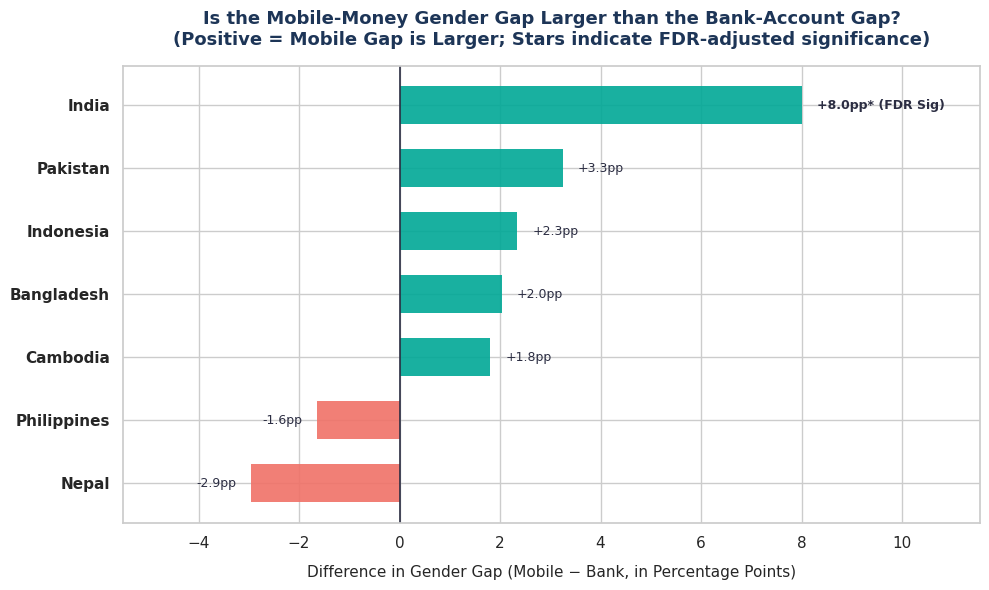

Successfully saved the gap comparison plot to '/content/channel_gap_comparison.png'.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Ensure polished style
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10

csv_path = "/content/day19_channel_gap_equality.csv"
if os.path.exists(csv_path):
    df_eq = pd.read_csv(csv_path)

    # Sort countries by the magnitude of the difference for a cleaner plot
    df_eq = df_eq.sort_values("diff_mobile_minus_bank", ascending=True)

    fig, ax = plt.subplots(figsize=(10, 6))

    # Map colors based on the value to highlight directional differences
    colors = ["#f07167" if val < 0 else "#00a896" for val in df_eq["diff_mobile_minus_bank"]]

    # Plot horizontal bars for the gap difference (mobile minus bank)
    y_pos = range(len(df_eq))
    bars = ax.barh(y_pos, df_eq["diff_mobile_minus_bank"] * 100, color=colors, height=0.6, edgecolor="none", alpha=0.9)

    # Customizing the ticks and labels
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_eq["economy"], fontsize=11, fontweight="bold")

    # Add a zero line reference
    ax.axvline(0, color="#2b2d42", linewidth=1.2, linestyle="-")

    # Put value labels on the bars
    for i, bar in enumerate(bars):
        width = bar.get_width()
        label_x = width + 0.3 if width >= 0 else width - 0.3
        align = "left" if width >= 0 else "right"
        # Highlight India as the only statistically significant difference after FDR
        is_sig = df_eq.iloc[i]["sig_prob_fdr"]
        weight = "bold" if is_sig else "normal"
        suffix = "* (FDR Sig)" if is_sig else ""
        ax.text(label_x, i, f"{width:+.1f}pp{suffix}", va="center", ha=align, fontsize=9, fontweight=weight, color="#2b2d42")

    ax.set_xlabel("Difference in Gender Gap (Mobile − Bank, in Percentage Points)", fontsize=11, labelpad=10)
    ax.set_title("Is the Mobile-Money Gender Gap Larger than the Bank-Account Gap?\n(Positive = Mobile Gap is Larger; Stars indicate FDR-adjusted significance)", fontsize=13, fontweight="bold", pad=15, color="#1d3557")

    # Add margin space on x-axis
    x_min, x_max = ax.get_xlim()
    ax.set_xlim(x_min - 2, x_max + 3)

    plt.tight_layout()
    plt.savefig("/content/channel_gap_comparison.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("Successfully saved the gap comparison plot to '/content/channel_gap_comparison.png'.")
else:
    print(f"Could not find '{csv_path}'. Please verify the script on Day 19 has been executed.")

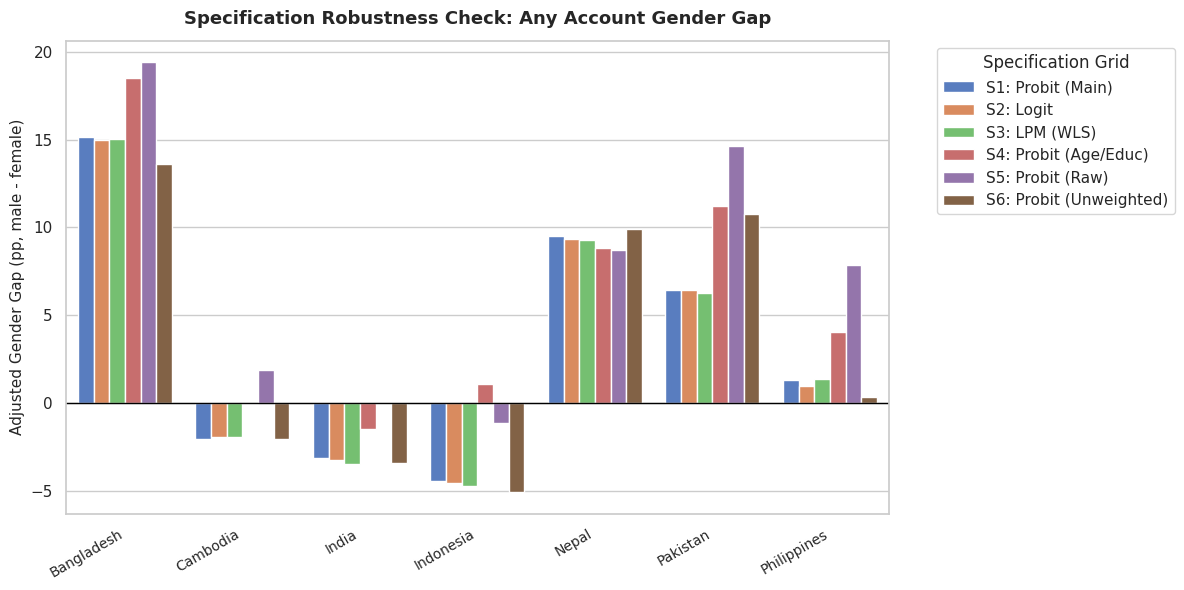

Successfully saved the plot to '/content/robustness_grid_any_account.png'.


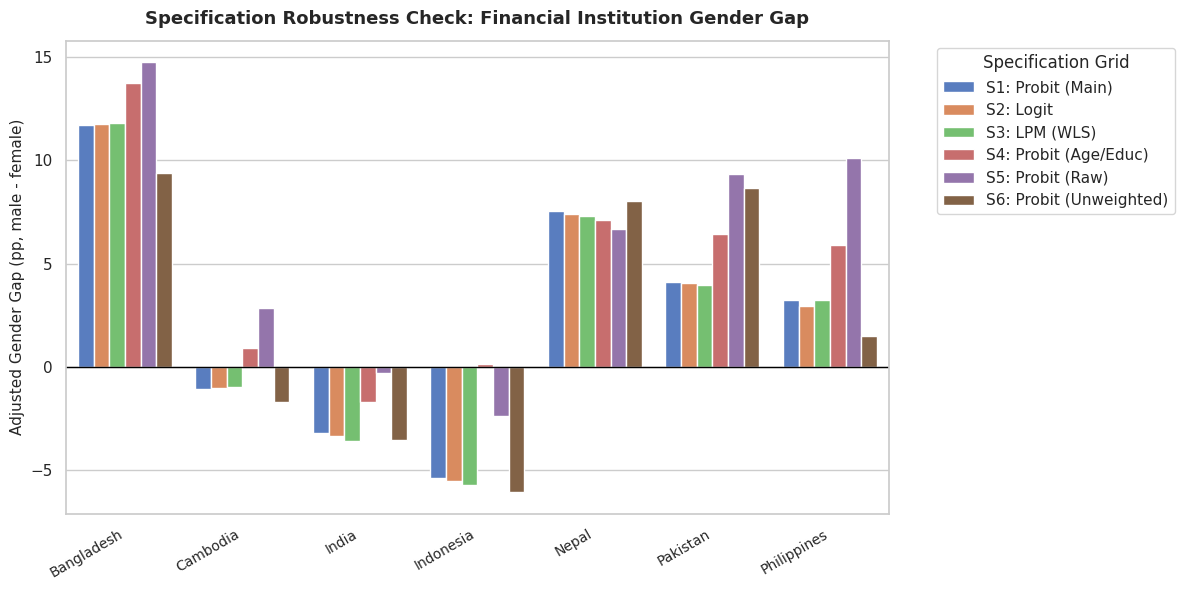

Successfully saved the plot to '/content/robustness_grid_financial_institution.png'.


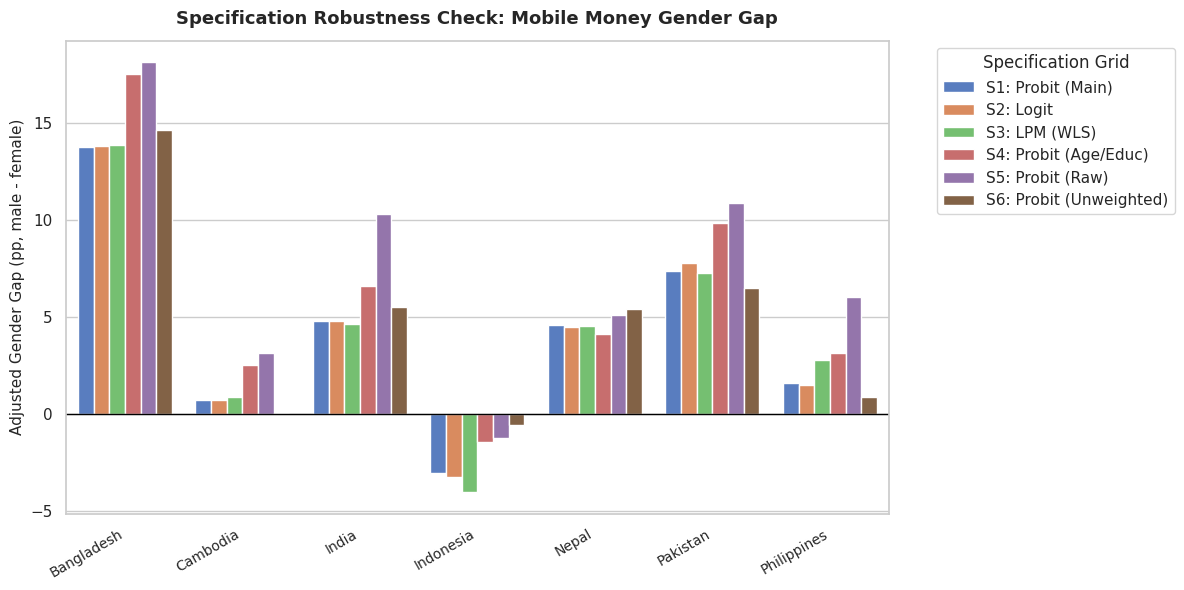

Successfully saved the plot to '/content/robustness_grid_mobile_money.png'.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Ensure clean styles
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10

csv_path = "/content/day20_robustness_grid.csv"
if os.path.exists(csv_path):
    df_grid = pd.read_csv(csv_path)

    # Melt the dataframe to long format for easier plotting with seaborn
    spec_cols = [
        "S1_probit_full_ame",
        "S2_logit_full_ame",
        "S3_lpm_full_ame",
        "S4_probit_age_educ_ame",
        "S5_probit_nocontrols_ame",
        "S6_probit_full_unweighted_ame"
    ]

    df_long = df_grid.melt(
        id_vars=["economy", "outcome", "verdict"],
        value_vars=spec_cols,
        var_name="specification",
        value_name="ame"
    )

    # Map clean names for specifications
    spec_map = {
        "S1_probit_full_ame": "S1: Probit (Main)",
        "S2_logit_full_ame": "S2: Logit",
        "S3_lpm_full_ame": "S3: LPM (WLS)",
        "S4_probit_age_educ_ame": "S4: Probit (Age/Educ)",
        "S5_probit_nocontrols_ame": "S5: Probit (Raw)",
        "S6_probit_full_unweighted_ame": "S6: Probit (Unweighted)"
    }
    df_long["specification"] = df_long["specification"].map(spec_map)

    # Map outcome labels
    df_long["outcome_label"] = df_long["outcome"].map({
        "account": "Any Account",
        "account_fin": "Financial Institution",
        "account_mob": "Mobile Money"
    })

    # Generate a plot for each outcome to avoid cluttering
    outcomes_ordered = ["Any Account", "Financial Institution", "Mobile Money"]

    for outcome in outcomes_ordered:
        sub_data = df_long[df_long["outcome_label"] == outcome]

        plt.figure(figsize=(12, 6))
        sns.barplot(
            data=sub_data,
            x="economy",
            y=sub_data["ame"] * 100,  # Convert to percentage points
            hue="specification",
            palette="muted"
        )
        plt.axhline(0, color="black", linewidth=1, linestyle="-")
        plt.ylabel("Adjusted Gender Gap (pp, male - female)", fontsize=11)
        plt.xlabel("", fontsize=11)
        plt.title(f"Specification Robustness Check: {outcome} Gender Gap", fontsize=13, fontweight="bold", pad=12)
        plt.xticks(rotation=30, ha="right", fontsize=10)
        plt.legend(title="Specification Grid", bbox_to_anchor=(1.05, 1), loc="upper left")
        plt.tight_layout()

        # Save each outcome's plot
        filename_label = outcome.lower().replace(" ", "_")
        plt.savefig(f"/content/robustness_grid_{filename_label}.png", dpi=200, bbox_inches="tight")
        plt.show()
        print(f"Successfully saved the plot to '/content/robustness_grid_{filename_label}.png'.")
else:
    print(f"Could not find '{csv_path}'. Please ensure the previous scripts have run successfully.")

In [ ]:
import os

# Verification block to ensure all expected visual assets were generated successfully
plots = [
    "/content/robustness_grid_any_account.png",
    "/content/robustness_grid_financial_institution.png",
    "/content/robustness_grid_mobile_money.png"
]

for plot_path in plots:
    exists = os.path.exists(plot_path)
    size = os.path.getsize(plot_path) if exists else 0
    print(f"{os.path.basename(plot_path)}: {'EXISTS' if exists else 'MISSING'} ({size / 1024:.1f} KB)")

robustness_grid_any_account.png: EXISTS (142.4 KB)
robustness_grid_financial_institution.png: EXISTS (140.7 KB)
robustness_grid_mobile_money.png: EXISTS (141.3 KB)


In [ ]:
# =============================================================================
# Global Findex 2021 - Day 21: correcting the six open issues in Thesis.ipynb
#
#   (1) Old-inference cells rerun with corrected inference
#         - Day 14 alternate outcomes + age cohorts      (notebook cell 21)
#         - Day 15-16 rural/urban interaction            (cell 22)
#         - Day 10-11 pooled female x country heterogeneity (cells 14-15)
#       Corrected = uniform person bootstrap (each resample fit with survey
#       weights) for AMEs, and cluster-by-row robust covariance for Wald tests.
#       Likelihood-ratio tests are NOT used (invalid under survey weights).
#   (3) Year check: confirms every analysis row is the 2021 wave.
#   (4) Fairlie decomposition: the explained share is reported as a RANGE across
#       the two reference choices, never as one number when the range is wide.
#   (5) Alternate outcomes are compared with the account result as "same sign
#       AND both FDR-significant", not "same significance bucket".
#   (6) Fairlie bootstrap CIs recomputed with a UNIFORM resample. The notebook
#       (cell 16) resampled with probability proportional to the weight and then
#       fit with the weights again, which counts the weights twice and gives CIs
#       that are too narrow. Same fix for the Day 8-9 AME CIs (cell 13).
#   (2) is a text fix (stale comments) and is done in the patched notebook.
#
# Input : findex_7country_clean.csv (Day 4-6)
# Env   : FINDEX_CSV, FINDEX_OUT, FINDEX_NBOOT (default 200; use 1000 for final),
#         FINDEX_RAW (optional path to the raw microdata, only for the year check
#         if the clean file has no `year` column),
#         FINDEX_SECTIONS (default "year,alt,age,rural,het,fairlie")
#
# NOT FIXABLE HERE: the cleaned file has no strata/PSU, so sampling-design
# clustering is not modelled; 2021 cross-section, so associations only.
# =============================================================================
# %%
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

np.random.seed(42)
DATA_PATH = os.environ.get("FINDEX_CSV", "/content/findex_7country_clean.csv")
OUT_DIR = os.environ.get("FINDEX_OUT", "/content")
N_BOOT = int(os.environ.get("FINDEX_NBOOT", 800))
RAW_PATH = os.environ.get("FINDEX_RAW", "")
SECTIONS = set(os.environ.get("FINDEX_SECTIONS", "year,alt,age,rural,het,fairlie").split(","))
PROBIT = sm.families.links.Probit()
MAIN = ["account", "account_fin", "account_mob"]
ALT = ["anydigpayment", "saved"]
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 40)


def banner(t):
    print("\n" + "=" * 100 + "\n" + t + "\n" + "=" * 100)


def pval(est, se):
    return 2 * stats.norm.sf(abs(est / se)) if se and np.isfinite(se) and se > 0 else np.nan


def bh_fdr(p):
    p = np.asarray(p, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    pv = p[ok]
    m = len(pv)
    if m == 0:
        return out
    o = np.argsort(pv)
    r = np.minimum.accumulate((pv[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    a = np.empty(m)
    a[o] = np.minimum(r, 1.0)
    out[ok] = a
    return out


# %%
# -----------------------------------------------------------------------------
# 0. LOAD
# -----------------------------------------------------------------------------
raw = pd.read_csv(DATA_PATH)
raw["inc_q"] = raw["inc_q"].astype("Int64")
inc_d = pd.get_dummies(raw["inc_q"], prefix="inc_q", drop_first=True).astype(float)
inc_cols = list(inc_d.columns)
raw = pd.concat([raw.drop(columns=[c for c in inc_cols if c in raw.columns]), inc_d], axis=1)
FULL = ["age", "age2", "educ_secondary", "educ_tertiary", "emp_in_d"] + inc_cols
COHORT_CTRL = ["educ_secondary", "educ_tertiary", "emp_in_d"] + inc_cols   # no age inside age bins, as in Day 14
countries = sorted(raw["economy"].unique())
# FINDEX_RURAL_CONTROL=1 (default, as in Day 8-9) adds rural_d as a control where available (all but the Philippines);
# =0 drops it everywhere in sections 2, 3 and 6, matching the Day 19/20 specification. Section 4 always uses rural_d.
RURAL_CONTROL = os.environ.get("FINDEX_RURAL_CONTROL", "1") == "1"
rural_avail = {c: raw.loc[raw["economy"] == c, "rural_d"].notna().mean() > 0.5
               if "rural_d" in raw.columns else False for c in countries}
rural_ok = dict(rural_avail) if RURAL_CONTROL else {c: False for c in countries}
print(f"rural_d as a control in sections 2, 3, 6: {'YES where available' if RURAL_CONTROL else 'NO (Day 19/20 specification)'}")
print(f"Loaded {len(raw):,} rows, {len(countries)} countries: {countries}")


def design(d, controls, extra=()):
    return sm.add_constant(d[["female_d"] + list(extra) + list(controls)].astype(float), has_constant="add")


def fit_probit(d, y, X, w):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return sm.GLM(y, X, family=sm.families.Binomial(link=PROBIT), freq_weights=w).fit()


def ame_female(d, outcome, controls, extra=()):
    """Weighted probit AME of being male vs female (male - female)."""
    X = design(d, controls, extra)
    w = d["wgt"].astype(float)
    fit = fit_probit(d, d[outcome].astype(float), X, w)
    X1 = X.copy(); X1["female_d"] = 1.0
    X0 = X.copy(); X0["female_d"] = 0.0
    return np.average(fit.predict(X0) - fit.predict(X1), weights=w)


def boot_draws(d, fn, n_boot=None, min_per_sex=30):
    """UNIFORM person bootstrap; fn(bs) is fit with the survey weights. Returns array of draws."""
    n_boot = n_boot or N_BOOT
    n = len(d); ar = np.arange(n); out = []
    for _ in range(n_boot):
        bs = d.iloc[np.random.choice(ar, size=n, replace=True)]
        if (bs["female_d"] == 1).sum() < min_per_sex or (bs["female_d"] == 0).sum() < min_per_sex:
            continue
        try:
            v = fn(bs)
            if np.all(np.isfinite(v)):
                out.append(v)
        except Exception:
            continue
    return np.array(out)


def ame_row(d, outcome, controls, extra=()):
    est = ame_female(d, outcome, controls, extra)
    dr = boot_draws(d, lambda b: ame_female(b, outcome, controls, extra))
    if len(dr) < 50:
        return dict(ame_pp=est * 100, se_pp=np.nan, ci_low_pp=np.nan, ci_high_pp=np.nan, p=np.nan, n_boot_ok=len(dr))
    se = dr.std(ddof=1)
    lo, hi = np.percentile(dr, [2.5, 97.5])
    return dict(ame_pp=est * 100, se_pp=se * 100, ci_low_pp=lo * 100, ci_high_pp=hi * 100,
                p=pval(est, se), n_boot_ok=len(dr))


# %%
# -----------------------------------------------------------------------------
# 1. YEAR CHECK  (issue 3)
# -----------------------------------------------------------------------------
if "year" in SECTIONS:
    banner("1. YEAR CHECK: is every analysis row from the 2021 wave?")
    yr = None
    if "year" in raw.columns:
        yr = raw.groupby("economy")["year"].value_counts().unstack(fill_value=0)
        print("Source: `year` column in the cleaned file.")
    elif RAW_PATH and os.path.exists(RAW_PATH):
        r0 = pd.read_csv(RAW_PATH, usecols=lambda c: c in ("economy", "year"))
        r0 = r0[r0["economy"].isin(countries)]
        yr = r0.groupby("economy")["year"].value_counts().unstack(fill_value=0)
        print(f"Source: `year` column in the raw file {RAW_PATH} (restricted to the 7 countries).")
    if yr is None:
        print("The cleaned file has no `year` column and FINDEX_RAW was not given. Run this on the RAW file "
              "(the 139-economy csv) and paste the result:\n"
              "  r = pd.read_csv('micro_world_139countries.csv', usecols=['economy','year'])\n"
              "  print(r[r.economy.isin(TARGET_COUNTRIES)].groupby('economy')['year'].value_counts())")
    else:
        print(yr.to_string())
        years = list(yr.columns)
        if years == [2021] or [int(y) for y in years] == [2021]:
            print("\nOK: all rows are 2021. State this in the Data section.")
        else:
            print(f"\nSTOP: rows from {years} are present. Filter to year == 2021 BEFORE any analysis, then rerun "
                  "everything, because every number so far would change.")

# %%
# -----------------------------------------------------------------------------
# 1b. AGE RANGE OF THE ANALYSIS SAMPLE (who is in the "adults" sample?)
# -----------------------------------------------------------------------------
if "year" in SECTIONS and "age" in raw.columns:
    banner("1b. AGE RANGE: min/max age, share under 18, and respondents outside the 18-24 / 25-54 / 55+ cohorts")
    a = raw.dropna(subset=["age"])
    rows = []
    for c in countries:
        x = a[a["economy"] == c]["age"]
        rows.append(dict(economy=c, n=len(x), age_min=int(x.min()), age_max=int(x.max()),
                         n_under_18=int((x < 18).sum()), pct_under_18=round(100 * (x < 18).mean(), 1),
                         n_outside_cohorts=int((x < 18).sum())))
    ar = pd.DataFrame(rows)
    print(ar.to_string(index=False))
    if (ar["n_under_18"] > 0).any():
        print("\nRespondents under 18 ARE in the main sample. The age-cohort analysis drops them (its bins start at 18). "
              "Say this in the Data section and call the sample 'respondents aged 15 and over' (or filter to 18+ "
              "and rerun everything). Do not call the sample 'adults' without this sentence.")
    else:
        print("\nNo respondents under 18: the cohort bins cover the whole sample.")
    ar.to_csv(os.path.join(OUT_DIR, "day21_age_range.csv"), index=False)

# %%
# -----------------------------------------------------------------------------
# 2. ALTERNATE OUTCOMES, corrected inference  (issues 1 and 5)
# -----------------------------------------------------------------------------
alt_res = None
if "alt" in SECTIONS:
    banner("2. ALTERNATE OUTCOMES (account usage / saving), uniform bootstrap, FDR within the alternate-outcome family")
    present = [o for o in ALT if o in raw.columns]
    if not present:
        print("anydigpayment / saved not in the cleaned file; skipped.")
    else:
        rows = []
        for c in countries:
            sub = raw[raw["economy"] == c]
            ctrl = FULL + (["rural_d"] if rural_ok[c] else [])
            for o in ["account"] + present:
                d = sub.dropna(subset=[o, "wgt", "female_d"] + ctrl).copy()
                for k in [o, "female_d"]:
                    d[k] = d[k].astype(float)
                r = ame_row(d, o, ctrl)
                r.update(economy=c, outcome=o, n=len(d))
                rows.append(r)
                print(f"  {c} - {o}: {r['ame_pp']:+.2f} pp (se {r['se_pp']:.2f})")
        alt_res = pd.DataFrame(rows)
        # FDR family = the alternate-outcome tests only (account rows are NOT in this family).
        is_alt = alt_res["outcome"] != "account"
        alt_res["p_fdr"] = np.nan
        alt_res.loc[is_alt, "p_fdr"] = bh_fdr(alt_res.loc[is_alt, "p"].values)
        alt_res["sig_fdr"] = np.where(alt_res["p_fdr"].isna(), np.nan, (alt_res["p_fdr"] < 0.05).astype(float))
        # Account significance comes from the Day 20 main family (21 tests), if that file is available.
        d20 = next((os.path.join(OUT_DIR, f) for f in ("day20_robustness_grid.csv", "robustness_grid.csv")
                    if os.path.exists(os.path.join(OUT_DIR, f))), "")
        if d20:
            g20 = pd.read_csv(d20)
            g20 = g20[g20["outcome"] == "account"].set_index("economy")["S1_sig_fdr"].astype(float)
            alt_res.loc[~is_alt, "sig_fdr"] = alt_res.loc[~is_alt, "economy"].map(g20).astype(float).values
            print(f"Account significance taken from the Day 20 main-spec FDR family ({os.path.basename(d20)}).")
        else:
            print("WARNING: day20_robustness_grid.csv / robustness_grid.csv not found in FINDEX_OUT; account significance below is NOT "
                  "from the main family. Put the Day 20 file there and rerun.")
            alt_res.loc[~is_alt, "sig_fdr"] = np.nan
        base = alt_res[alt_res["outcome"] == "account"].set_index("economy")
        alt_res["account_ame_pp"] = alt_res["economy"].map(base["ame_pp"])
        alt_res["account_sig_fdr"] = alt_res["economy"].map(base["sig_fdr"]) == 1.0
        alt_res["same_sign_as_account"] = np.sign(alt_res["ame_pp"]) == np.sign(alt_res["account_ame_pp"])
        alt_res["both_sig_same_sign"] = alt_res["same_sign_as_account"] & (alt_res["sig_fdr"] == 1.0) & alt_res["account_sig_fdr"]
        show = alt_res[alt_res["outcome"] != "account"][
            ["economy", "outcome", "n", "ame_pp", "se_pp", "ci_low_pp", "ci_high_pp", "p_fdr", "sig_fdr",
             "account_ame_pp", "account_sig_fdr", "same_sign_as_account", "both_sig_same_sign"]]
        print("\n" + show.round(3).to_string(index=False))
        for o in present:
            s = show[show["outcome"] == o]
            print(f"\n{o}: FDR-significant in {int((s['sig_fdr'] == 1.0).sum())}/{len(s)} countries; "
                  f"same sign as account in {int(s['same_sign_as_account'].sum())}/{len(s)}; "
                  f"significant AND same sign as a significant account gap in {int(s['both_sig_same_sign'].sum())}.")
        print("\nWriting rule: say 'usage and saving do not mirror ownership' for any country where the sign differs "
              "or only one of the two is FDR-significant. Do not write 'results hold across outcomes'.")
        alt_res.to_csv(os.path.join(OUT_DIR, "day21_alt_outcomes.csv"), index=False)

# %%
# -----------------------------------------------------------------------------
# 3. AGE COHORTS, corrected inference  (issue 1)
# -----------------------------------------------------------------------------
if "age" in SECTIONS:
    banner("3. AGE COHORTS (18-24 / 25-54 / 55+), uniform bootstrap, FDR over all cells")
    BINS = [(18, 24, "18-24"), (25, 54, "25-54"), (55, 120, "55+")]
    rows, skipped = [], []
    for c in countries:
        sub = raw[raw["economy"] == c]
        ctrl = COHORT_CTRL + (["rural_d"] if rural_ok[c] else [])
        for lo, hi, lab in BINS:
            for o in MAIN:
                d = sub[(sub["age"] >= lo) & (sub["age"] <= hi)].dropna(subset=[o, "wgt", "female_d"] + ctrl).copy()
                d[o] = d[o].astype(float); d["female_d"] = d["female_d"].astype(float)
                nm, nf = int((d["female_d"] == 0).sum()), int((d["female_d"] == 1).sum())
                pos = int(d[o].sum())
                if nm < 30 or nf < 30 or pos < 10 or (len(d) - pos) < 10:
                    skipped.append((c, lab, o, nm, nf, pos))
                    continue
                try:
                    r = ame_row(d, o, ctrl)
                except Exception:
                    skipped.append((c, lab, o, nm, nf, pos)); continue
                r.update(economy=c, age_bin=lab, outcome=o, n=len(d), n_male=nm, n_female=nf)
                rows.append(r)
    pd.DataFrame(skipped, columns=["economy", "age_bin", "outcome", "n_male", "n_female", "n_events"]).to_csv(
        os.path.join(OUT_DIR, "day21_age_skipped.csv"), index=False)
    age_res = pd.DataFrame(rows)
    age_res["p_fdr"] = bh_fdr(age_res["p"].values)
    age_res["sig_fdr"] = age_res["p_fdr"] < 0.05
    print(f"{len(age_res)} cohort models completed, {len(skipped)} skipped (a sex <30, or <10 events/non-events).")
    pv = age_res.pivot_table(index=["economy", "outcome"], columns="age_bin", values="ame_pp")
    print("\nAME (pp, male - female) by cohort:\n" + pv.round(1).to_string())
    flips = []
    for (c, o), g in age_res.groupby(["economy", "outcome"]):
        s = g[g["sig_fdr"]]
        if (s["ame_pp"] > 0).any() and (s["ame_pp"] < 0).any():
            flips.append((c, o))
    print(f"\nConfirmed reversals (opposite signs, BOTH FDR-significant): {flips if flips else 'none'}")
    print("Cohort differences are NOT formally tested here. Describe them as 'not distinguishable' unless a "
          "formal cohort interaction test is added.")
    age_res.to_csv(os.path.join(OUT_DIR, "day21_age_cohorts.csv"), index=False)

    # ---- 3b. FORMAL cohort-interaction test: does the female gap differ across age cohorts? ----
    banner("3b. AGE x FEMALE interaction (joint Wald, 2 df, cluster-by-row), FDR over tests")
    rows = []
    for c in countries:
        sub = raw[raw["economy"] == c]
        ctrl = COHORT_CTRL + (["rural_d"] if rural_ok[c] else [])
        for o in MAIN:
            d = sub.dropna(subset=[o, "wgt", "female_d", "age"] + ctrl).copy().reset_index(drop=True)
            d["bin"] = pd.cut(d["age"], [17, 24, 54, 200], labels=["b1824", "b2554", "b55p"])
            d = d.dropna(subset=["bin"]).reset_index(drop=True)
            d[o] = d[o].astype(float); d["female_d"] = d["female_d"].astype(float)
            ok = True
            for lab, g in d.groupby("bin", observed=True):
                pos = int(g[o].sum())
                if (g["female_d"] == 0).sum() < 30 or (g["female_d"] == 1).sum() < 30 or pos < 10 or len(g) - pos < 10:
                    ok = False
            if not ok or d["bin"].nunique() < 3:
                rows.append(dict(economy=c, outcome=o, n=len(d), chi2=np.nan, df=2, wald_p=np.nan, tested=False))
                continue
            d["young"] = (d["bin"] == "b1824").astype(float)
            d["old"] = (d["bin"] == "b55p").astype(float)
            d["f_young"] = d["female_d"] * d["young"]
            d["f_old"] = d["female_d"] * d["old"]
            X = sm.add_constant(d[["female_d", "young", "old", "f_young", "f_old"] + ctrl].astype(float), has_constant="add")
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fit = sm.GLM(d[o], X, family=sm.families.Binomial(link=PROBIT), freq_weights=d["wgt"].astype(float)
                                 ).fit(cov_type="cluster", cov_kwds={"groups": np.arange(len(d))})
                names = list(fit.params.index)
                R = np.zeros((2, len(names)))
                R[0, names.index("f_young")] = 1.0
                R[1, names.index("f_old")] = 1.0
                wt = fit.wald_test(R, scalar=True)
                rows.append(dict(economy=c, outcome=o, n=len(d), chi2=float(wt.statistic), df=2,
                                 wald_p=float(wt.pvalue), tested=True))
            except Exception:
                rows.append(dict(economy=c, outcome=o, n=len(d), chi2=np.nan, df=2, wald_p=np.nan, tested=False))
    age_int = pd.DataFrame(rows)
    age_int["p_fdr"] = bh_fdr(age_int["wald_p"].values)
    age_int["sig_fdr"] = age_int["p_fdr"] < 0.05
    print(age_int.round(4).sort_values("wald_p").to_string(index=False))
    print(f"\n{int(age_int['tested'].sum())} tests run, {int((~age_int['tested']).sum())} skipped (a cohort too thin); "
          f"{int(age_int['sig_fdr'].fillna(False).sum())} survive FDR.")
    print("Only describe a cohort pattern as real where sig_fdr is True. The three cohort AMEs above are "
          "descriptive otherwise.")
    age_int.to_csv(os.path.join(OUT_DIR, "day21_age_interaction.csv"), index=False)

# %%
# -----------------------------------------------------------------------------
# 4. RURAL / URBAN INTERACTION, corrected inference  (issue 1)
# -----------------------------------------------------------------------------
if "rural" in SECTIONS:
    banner("4. RURAL x FEMALE interaction (cluster-by-row Wald), FDR over all tests")
    rows = []
    for c in countries:
        if not rural_avail[c]:
            print(f"  {c}: no usable rural_d, excluded (state as a coverage limitation).")
            continue
        sub = raw[raw["economy"] == c]
        for o in MAIN:
            d = sub.dropna(subset=[o, "wgt", "female_d", "rural_d"] + FULL).copy().reset_index(drop=True)
            d[o] = d[o].astype(float); d["female_d"] = d["female_d"].astype(float); d["rural_d"] = d["rural_d"].astype(float)
            d["female_x_rural"] = d["female_d"] * d["rural_d"]
            X = sm.add_constant(d[["female_d", "rural_d", "female_x_rural"] + FULL].astype(float), has_constant="add")
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = sm.GLM(d[o], X, family=sm.families.Binomial(link=PROBIT), freq_weights=d["wgt"].astype(float)
                             ).fit(cov_type="cluster", cov_kwds={"groups": np.arange(len(d))})
            b, se = fit.params["female_x_rural"], fit.bse["female_x_rural"]
            rows.append(dict(economy=c, outcome=o, n=len(d), interaction_coef=b, se=se, wald_p=pval(b, se)))
    rur = pd.DataFrame(rows)
    rur["p_fdr"] = bh_fdr(rur["wald_p"].values)
    rur["sig_fdr"] = rur["p_fdr"] < 0.05
    print(rur.round(4).sort_values("wald_p").to_string(index=False))
    print(f"\n{int(rur['sig_fdr'].sum())} / {len(rur)} interaction tests survive FDR (alpha .05).")
    print("Negative coefficient = the female disadvantage is larger in rural areas (index scale).")
    rur.to_csv(os.path.join(OUT_DIR, "day21_rural_interaction.csv"), index=False)

# %%
# -----------------------------------------------------------------------------
# 5. POOLED HETEROGENEITY: does the female effect differ across countries?  (issue 1)
#    Replaces the Wald/LR test of cells 14-15. Equal-country weights are built
#    here (each country's weights sum to N/7), country fixed effects, female x
#    country terms, cluster-by-row covariance, joint Wald test (6 df).
# -----------------------------------------------------------------------------
if "het" in SECTIONS:
    banner("5. POOLED HETEROGENEITY of the female coefficient across countries (joint Wald, 6 df)")
    cols_need = ["female_d", "wgt"] + MAIN + FULL
    d0 = raw.dropna(subset=cols_need).copy().reset_index(drop=True)
    d0["w_eq"] = d0["wgt"] / d0.groupby("economy")["wgt"].transform("sum") * (len(d0) / len(countries))
    base_c = countries[0]
    rows = []
    for o in MAIN:
        X = d0[["female_d"] + FULL].astype(float).copy()
        het = []
        for k in countries[1:]:
            fe = (d0["economy"] == k).astype(float)
            X["fe_" + k] = fe
            X["female_x_" + k] = d0["female_d"] * fe
            het.append("female_x_" + k)
        X = sm.add_constant(X, has_constant="add")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = sm.GLM(d0[o].astype(float), X, family=sm.families.Binomial(link=PROBIT), freq_weights=d0["w_eq"]
                         ).fit(cov_type="cluster", cov_kwds={"groups": np.arange(len(d0))})
        names = list(fit.params.index)
        R = np.zeros((len(het), len(names)))
        for i, h in enumerate(het):
            R[i, names.index(h)] = 1.0
        wt = fit.wald_test(R, scalar=True)
        rows.append(dict(outcome=o, reference_country=base_c, chi2=float(wt.statistic), df=len(het), p=float(wt.pvalue)))
    het_res = pd.DataFrame(rows)
    print(het_res.round(5).to_string(index=False))
    print("A small p means the female coefficient is not common across countries. This replaces the earlier "
          "'Wald/LR chi2(6), p<.001' statement, which used the invalid covariance.")
    het_res.to_csv(os.path.join(OUT_DIR, "day21_pooled_heterogeneity.csv"), index=False)

# %%
# -----------------------------------------------------------------------------
# 6. FAIRLIE DECOMPOSITION with UNIFORM-resample CIs and range reporting  (issues 4, 6)
# -----------------------------------------------------------------------------
def fit_group(d, outcome, preds):
    X = sm.add_constant(d[preds].astype(float), has_constant="add")
    return fit_probit(d, d[outcome].astype(float), X, d["wgt"].astype(float)), X, d["wgt"].astype(float)


def fairlie(dm, df_, outcome, preds):
    fm, Xm, wm = fit_group(dm, outcome, preds)
    ff, Xf, wf = fit_group(df_, outcome, preds)
    cols = ["const"] + preds
    Xm_, Xf_ = Xm[cols].values, Xf[cols].values
    bm, bf = fm.params[cols].values, ff.params[cols].values
    F = PROBIT.inverse
    p_m_bm, p_f_bm, p_m_bf, p_f_bf = F(Xm_ @ bm), F(Xf_ @ bm), F(Xm_ @ bf), F(Xf_ @ bf)
    av = np.average
    total = av(p_m_bm, weights=wm) - av(p_f_bf, weights=wf)
    e_m = av(p_m_bm, weights=wm) - av(p_f_bm, weights=wf)
    e_f = av(p_m_bf, weights=wm) - av(p_f_bf, weights=wf)
    return np.array([total, e_m, e_f, (e_m + e_f) / 2])   # total, explained(male ref), explained(female ref), midpoint


if "fairlie" in SECTIONS:
    banner("6. FAIRLIE: explained share as a RANGE; CIs from a uniform person bootstrap")
    rows = []
    for c in countries:
        preds = FULL + (["rural_d"] if rural_ok[c] else [])
        sub = raw[raw["economy"] == c]
        for o in MAIN:
            d = sub.dropna(subset=[o, "wgt", "female_d"] + preds).copy()
            d[o] = d[o].astype(float); d["female_d"] = d["female_d"].astype(float)

            def fn(b, o=o, preds=preds):
                return fairlie(b[b["female_d"] == 0], b[b["female_d"] == 1], o, preds)

            try:
                point = fn(d)
            except Exception as e:
                print(f"  {c} - {o}: FAILED ({e})")
                continue
            dr = boot_draws(d, fn)
            ok = len(dr)
            if ok < 50:
                print(f"  {c} - {o}: only {ok} valid bootstrap reps, CIs withheld.")
                ci = np.full((2, 4), np.nan)
            else:
                ci = np.percentile(dr, [2.5, 97.5], axis=0)
                if ok < 0.9 * N_BOOT:
                    print(f"  NOTE {c} - {o}: {ok}/{N_BOOT} valid reps (possible quasi-separation).")
            tot, e_m, e_f, mid = point * 100
            rng_lo, rng_hi = min(e_m, e_f), max(e_m, e_f)
            ref_range = rng_hi - rng_lo
            gap_excl_zero = bool(np.isfinite(ci[0, 0]) and (ci[0, 0] > 0 or ci[1, 0] < 0))
            # NOTE: 0.5 here is only a first screen. The paper tables (cell 29) apply the stricter 25% rule
            # (reference range <= 0.25 x |gap|). Quote explained shares from paper_tables.xlsx, not from this printout.
            report_share = (abs(tot) >= 5) and (ref_range <= 0.5 * abs(tot)) and gap_excl_zero
            rows.append(dict(
                economy=c, outcome=o, n=len(d), total_gap_pp=tot,
                total_ci_low=ci[0, 0] * 100, total_ci_high=ci[1, 0] * 100,
                expl_male_ref_pp=e_m, expl_female_ref_pp=e_f, expl_mid_pp=mid,
                expl_mid_ci_low=ci[0, 3] * 100, expl_mid_ci_high=ci[1, 3] * 100,
                expl_range_pp=f"{rng_lo:.1f} to {rng_hi:.1f}", ref_range_pp=ref_range,
                share_explained_pct=(100 * mid / tot) if report_share else np.nan,
                share_reportable=bool(report_share), n_boot_ok=ok))
            print(f"  {c} - {o}: gap {tot:+.2f}, explained {rng_lo:.1f} to {rng_hi:.1f} pp")
    fl = pd.DataFrame(rows)
    show = fl[["economy", "outcome", "total_gap_pp", "total_ci_low", "total_ci_high", "expl_mid_pp",
               "expl_mid_ci_low", "expl_mid_ci_high", "expl_range_pp", "ref_range_pp", "share_reportable"]]
    print("\n" + show.round(2).to_string(index=False))
    print(f"\nShare-explained is reportable in {int(fl['share_reportable'].sum())}/{len(fl)} cells "
          "(|gap| >= 5 pp, its bootstrap CI excludes 0, AND the two reference choices differ by <= half the gap).")
    print("Writing rule: where share_reportable is False, report the explained RANGE, and say the split between "
          "composition and returns is not pinned down by this design. Do not quote a single explained share.")
    fl.to_csv(os.path.join(OUT_DIR, "day21_fairlie_corrected.csv"), index=False)

print("\nDone. Outputs in", OUT_DIR, "(files named day21_*.csv)")

rural_d as a control in sections 2, 3, 6: YES where available
Loaded 9,062 rows, 7 countries: ['Bangladesh', 'Cambodia', 'India', 'Indonesia', 'Nepal', 'Pakistan', 'Philippines']

1. YEAR CHECK: is every analysis row from the 2021 wave?
Source: `year` column in the cleaned file.
year         2021
economy          
Bangladesh   1000
Cambodia     1000
India        3000
Indonesia    1062
Nepal        1000
Pakistan     1001
Philippines   999

OK: all rows are 2021. State this in the Data section.

1b. AGE RANGE: min/max age, share under 18, and respondents outside the 18-24 / 25-54 / 55+ cohorts
    economy    n  age_min  age_max  n_under_18  pct_under_18  n_outside_cohorts
 Bangladesh 1000       15       90          55        5.5000                 55
   Cambodia 1000       15       99          62        6.2000                 62
      India 3000       15       90         158        5.3000                158
  Indonesia 1062       15       85          69        6.5000                 69
 

In [ ]:
# =============================================================================
# Global Findex 2021 - Day 21b: consolidated paper tables (one workbook)
#
# Reads the CSVs your earlier scripts wrote, converts everything to the same
# units (percentage points), and writes ONE workbook, paper_tables.xlsx, so that
# every number in the paper comes from one place.
#
#   T1_sample           sample accounting, Kish design effect, effective n
#   T2_main             main-spec AME by country x outcome (FDR, verdict, power)
#   T3_channel          cross-channel equality test (mobile gap minus bank gap)
#   T4_fairlie          Fairlie decomposition, corrected CIs, explained RANGE
#   A1_alt_outcomes     digital payment / saving
#   A2_age_ame          age-cohort AMEs (descriptive)
#   A2b_age_interaction formal age x female test
#   A3_rural            rural x female interaction
#   A4_heterogeneity    pooled female x country test
#   CHECKS              consistency checks between files (read these first)
#   PROVENANCE          which file, when written, how many rows, bootstrap reps
#
# Env: FINDEX_OUT (folder with the CSVs, default /content)
#      PAPER_XLSX (output path, default <FINDEX_OUT>/paper_tables.xlsx)
# Nothing is estimated here; it only reads, converts, checks and writes.
# =============================================================================
# %%
import os
import time
import numpy as np
import pandas as pd

OUT_DIR = os.environ.get("FINDEX_OUT", "/content")
XLSX = os.environ.get("PAPER_XLSX", os.path.join(OUT_DIR, "paper_tables.xlsx"))

# Several file names are accepted, because the notebook saved some of them under other names.
CANDIDATES = {
    "sample":   ["day20_sample_accounting.csv", "sample_accounting.csv"],
    "grid":     ["day20_robustness_grid.csv", "robustness_grid.csv"],
    "channel":  ["day19_channel_gap_equality.csv", "channel_gap_equality.csv"],
    "loo":      ["day20_pooled_leave_one_out.csv", "pooled_leave_one_out.csv"],
    "alt":      ["day21_alt_outcomes.csv"],
    "age":      ["day21_age_cohorts.csv"],
    "age_int":  ["day21_age_interaction.csv"],
    "rural":    ["day21_rural_interaction.csv"],
    "het":      ["day21_pooled_heterogeneity.csv"],
    "fairlie":  ["day21_fairlie_corrected.csv"],
    "age_range": ["day21_age_range.csv"],
    "age_skipped": ["day21_age_skipped.csv"],
}
found, tables, prov = {}, {}, []
for key, names in CANDIDATES.items():
    path = next((os.path.join(OUT_DIR, n) for n in names if os.path.exists(os.path.join(OUT_DIR, n))), None)
    if path is None:
        print(f"MISSING: {key} (looked for {names})")
        continue
    df = pd.read_csv(path)
    tables[key] = df
    nb = df["n_boot_ok"] if "n_boot_ok" in df.columns else (df["n_boot_requested"] if "n_boot_requested" in df.columns else None)
    prov.append(dict(table=key, file=os.path.basename(path),
                     written=time.strftime("%Y-%m-%d %H:%M", time.localtime(os.path.getmtime(path))),
                     rows=len(df),
                     boot_reps_min=int(nb.min()) if nb is not None and nb.notna().any() else np.nan,
                     boot_reps_max=int(nb.max()) if nb is not None and nb.notna().any() else np.nan))
prov = pd.DataFrame(prov)
checks = []


def add_check(name, ok, detail):
    checks.append(dict(check=name, status="OK" if ok else "LOOK", detail=detail))


def r(df, cols, nd=2):
    df = df.copy()
    for c in cols:
        if c in df.columns:
            df[c] = df[c].round(nd)
    return df


sheets = {}

# ---- T1 ---------------------------------------------------------------------
if "sample" in tables:
    t = tables["sample"].copy()
    sheets["T1_sample"] = r(t, ["pct_lost_full", "kish_deff_weights", "n_effective"])

# ---- T2 ---------------------------------------------------------------------
if "grid" in tables:
    g = tables["grid"].copy()
    t = pd.DataFrame({
        "economy": g["economy"], "outcome": g["outcome"], "n": g["n"],
        "AME_pp": g["S1_probit_full_ame"] * 100, "SE_pp": g["S1_probit_full_se"] * 100,
        "CI_low_pp": (g["S1_probit_full_ame"] - 1.96 * g["S1_probit_full_se"]) * 100,
        "CI_high_pp": (g["S1_probit_full_ame"] + 1.96 * g["S1_probit_full_se"]) * 100,
        "p": g["S1_probit_full_p"], "p_fdr": g["S1_p_fdr"], "sig_fdr": g["S1_sig_fdr"],
        "verdict": g["verdict"], "MDE80_pp": g["mde80_pp"] if "mde80_pp" in g.columns else np.nan})
    sheets["T2_main"] = r(t, ["AME_pp", "SE_pp", "CI_low_pp", "CI_high_pp", "MDE80_pp"]).round({"p": 4, "p_fdr": 4})
    add_check("T2 CI is normal-approximation (AME +/- 1.96 SE)", True,
              "The Day 20 grid stores SEs, not percentile CIs; CIs here are AME +/- 1.96 SE. Say so in the table note.")

# ---- T3 ---------------------------------------------------------------------
if "channel" in tables:
    c = tables["channel"].copy()
    keep = {"economy": "economy", "n": "n"}
    t = pd.DataFrame({"economy": c["economy"], "n": c["n"],
                      "bank_gap_pp": c["ame_gap_bank"] * 100, "mobile_gap_pp": c["ame_gap_mobile"] * 100,
                      "diff_mobile_minus_bank_pp": c["diff_mobile_minus_bank"] * 100,
                      "CI_low_pp": c["ci_low"] * 100, "CI_high_pp": c["ci_high"] * 100,
                      "p": c["p_prob"], "p_fdr": c["p_prob_fdr"],
                      "b_female_x_mob": c["b_female_x_mob"], "p_index_fdr": c.get("p_index_fdr", np.nan)})
    sheets["T3_channel"] = r(t, ["bank_gap_pp", "mobile_gap_pp", "diff_mobile_minus_bank_pp", "CI_low_pp",
                                  "CI_high_pp", "b_female_x_mob"]).round({"p": 4, "p_fdr": 4, "p_index_fdr": 4})
    if "loo" in tables:
        l = r(tables["loo"], ["coef", "se"], 4)
        l["p"] = l["p"].map(lambda v: "<0.001" if v < 0.001 else f"{v:.4f}")
        sheets["T3b_pooled_loo"] = l

# ---- T4 / appendices --------------------------------------------------------
if "fairlie" in tables:
    f = tables["fairlie"].copy()
    f["explained_range_pp"] = f["expl_range_pp"]
    # Stricter rule than the Day 21 script: quote a share only if |gap| >= 5 pp, its CI excludes 0, and the two
    # reference choices differ by at most 25% of the gap (the script used 50%).
    gap_ok = (f["total_ci_low"] > 0) | (f["total_ci_high"] < 0)
    f["share_reportable"] = (f["total_gap_pp"].abs() >= 5) & gap_ok & (f["ref_range_pp"] <= 0.25 * f["total_gap_pp"].abs())
    f["share_explained_pct"] = np.where(f["share_reportable"], 100 * f["expl_mid_pp"] / f["total_gap_pp"], np.nan).round(0)
    lo_s = 100 * f[["expl_male_ref_pp", "expl_female_ref_pp"]].min(axis=1) / f["total_gap_pp"]
    hi_s = 100 * f[["expl_male_ref_pp", "expl_female_ref_pp"]].max(axis=1) / f["total_gap_pp"]
    lo_s, hi_s = np.minimum(lo_s, hi_s), np.maximum(lo_s, hi_s)

    def how(i):
        row = f.loc[i]
        if not row["share_reportable"]:
            return f"explained part {row['explained_range_pp']} pp; do NOT quote a share"
        if row["expl_mid_pp"] <= 0:
            return "composition explains none of the gap (explained part is zero or negative)"
        return f"share explained {lo_s[i]:.0f} to {hi_s[i]:.0f}% (across the two reference groups)"
    f["how_to_report"] = [how(i) for i in f.index]
    tables["fairlie"] = f
    sheets["T4_fairlie"] = r(f.drop(columns=["expl_range_pp"]), [c for c in f.columns if c.endswith("_pp")
                                                                or c.endswith("_low") or c.endswith("_high")]
                             ).round(2)
if "grid" in tables:
    g = tables["grid"]
    cols = {"S1": "S1_probit_full", "S2": "S2_logit_full", "S3": "S3_lpm_full", "S4": "S4_probit_age_educ",
            "S5": "S5_probit_nocontrols", "S6": "S6_probit_full_unweighted"}
    t = g[["economy", "outcome", "n"]].copy()
    for k, c in cols.items():
        if c + "_ame" in g.columns:
            t[k + "_AME_pp"] = g[c + "_ame"] * 100
            if c + "_p" in g.columns:
                t[k + "_p"] = g[c + "_p"]
    t["verdict"] = g["verdict"]
    sheets["A5_robustness_grid"] = t.round(3)
if "alt" in tables:
    sheets["A1_alt_outcomes"] = r(tables["alt"], ["ame_pp", "se_pp", "ci_low_pp", "ci_high_pp", "account_ame_pp"]).round({"p": 4, "p_fdr": 4})
AGE_DROPPED = []
if "age" in tables:
    a = tables["age"].copy()
    mx = a["n_boot_ok"].max()
    a["cell_status"] = np.where(a["n_boot_ok"] < 0.7 * mx, "DROPPED (fewer than 70% of resamples converged)",
                         np.where(a["n_boot_ok"] < 0.9 * mx, "FLAG (10-30% of resamples did not converge)", "ok"))
    _dr = a.loc[a["cell_status"].str.startswith("DROPPED"), ["economy", "age_bin", "outcome"]].astype(str)
    AGE_DROPPED = [" / ".join(r_) for r_ in _dr.values.tolist()]
    a = a[~a["cell_status"].str.startswith("DROPPED")]
    sheets["A2_age_ame"] = r(a, ["ame_pp", "se_pp", "ci_low_pp", "ci_high_pp"]).round({"p": 4, "p_fdr": 4})
if "age_int" in tables:
    sheets["A2b_age_interaction"] = r(tables["age_int"], ["chi2"]).round({"wald_p": 4, "p_fdr": 4})
if "rural" in tables:
    sheets["A3_rural"] = r(tables["rural"], ["interaction_coef", "se"], 4).round({"wald_p": 4, "p_fdr": 4})
if "het" in tables:
    sheets["A4_heterogeneity"] = r(tables["het"], ["chi2"]).assign(p_exact=tables["het"]["p"].map(lambda x: f"{x:.2e}")).drop(columns=["p"])

# ---- CHECKS -----------------------------------------------------------------
# 1. Bootstrap reps consistent across Day 21 tables
reps = prov.dropna(subset=["boot_reps_max"])
if len(reps):
    mx = reps["boot_reps_max"].unique()
    add_check("Same bootstrap size across Day 21 tables", len(mx) == 1,
              f"max valid reps per table: {dict(zip(reps['table'], reps['boot_reps_max'].astype(int)))}. "
              "If the maxima differ, the tables were run with different FINDEX_NBOOT; rerun them together.")
    thin = reps[reps["boot_reps_min"] < 0.9 * reps["boot_reps_max"]]
    cells = []
    for tname in thin["table"]:
        d = tables[tname]
        bad = d[d["n_boot_ok"] < 0.9 * d["n_boot_ok"].max()]
        idc = [c for c in ("economy", "age_bin", "outcome") if c in bad.columns]
        cells += [tname + ": " + " / ".join(str(x) for x in row) + f" ({int(n)} reps)"
                  for row, n in zip(bad[idc].values.tolist(), bad["n_boot_ok"])]
    add_check("No table lost >10% of its bootstrap reps", thin.empty,
              ("cells with thin reps (flag as unreliable or drop): " + "; ".join(cells)) if cells else "none")

# 2. Same specification across files: Day 20 S1 AME vs Day 21 account AME
if "grid" in tables and "alt" in tables:
    a = tables["alt"]; a = a[a["outcome"] == "account"][["economy", "ame_pp"]]
    g = tables["grid"]; g = g[g["outcome"] == "account"][["economy", "S1_probit_full_ame"]]
    m = a.merge(g, on="economy")
    if len(m):
        m["diff_pp"] = m["ame_pp"] - m["S1_probit_full_ame"] * 100
        worst = m["diff_pp"].abs().max()
        se_ref = float(np.nanmedian(tables["grid"]["S1_probit_full_se"]) * 100)
        add_check("Controls identical in Day 20 and Day 21 (account AME)", worst < 0.1 * se_ref,
                  f"largest |difference| = {worst:.2f} pp (OK if under 10% of the median SE, {0.1*se_ref:.2f} pp). Day 20 omits rural_d; Day 21 (like Day 8-9 and the Fairlie "
                  "cells) adds it where available. If the difference is larger, the main table and the "
                  "decomposition use different control sets: choose ONE and rerun, or state each table's controls in its note. "
                  + "; ".join(f"{e}: {d:+.2f}" for e, d in zip(m["economy"], m["diff_pp"])))
    else:
        add_check("Controls identical in Day 20 and Day 21 (account AME)", False, "economy names did not match between files")

# 3. Fairlie total gap vs raw-controls gap sanity: total gap CI present
if "fairlie" in tables:
    nr = int(tables["fairlie"]["share_reportable"].sum())
    add_check("Fairlie share-explained reportable cells", True,
              f"{nr}/{len(tables['fairlie'])}. Elsewhere report the explained range only.")

# 4. FDR families stated
add_check("FDR families", True,
          "T2: 21 main tests (Day 20). T3: 7 country tests. A1: 14 alternate-outcome tests. A2b/A3/A4: their own tests. "
          "State each family in the table notes; never mix them.")

# 5. Sample consistency
if "sample" in tables and "channel" in tables:
    s = tables["sample"].set_index("economy")["n_complete_full"]
    ch = tables["channel"].set_index("economy")["n"]
    same = (s.reindex(ch.index) == ch).all()
    add_check("Sample sizes agree between Day 19 and Day 20", bool(same),
              f"Day 20: {s.to_dict()} | Day 19: {ch.to_dict()}")

# 6. Bootstrap size known for Day 19 / Day 20 tables?
for key, label in (("channel", "Day 19 (T3)"), ("grid", "Day 20 (T2, A5)")):
    if key in tables:
        known = ("n_boot_requested" in tables[key].columns)
        add_check(f"Bootstrap size recorded for {label}", known,
                  "recorded in the file" if known else
                  "the file has no n_boot_requested column (written by an older run). Rerun that script, or confirm "
                  "FINDEX_NBOOT yourself, before quoting its CIs.")
if "channel" in tables and "n_boot_requested" in tables["channel"].columns and "alt" in tables:
    same = tables["channel"]["n_boot_requested"].max() == tables["alt"]["n_boot_ok"].max()
    add_check("Day 19 bootstrap size equals the Day 21 size", bool(same),
              f"Day 19: {int(tables['channel']['n_boot_requested'].max())}, Day 21: {int(tables['alt']['n_boot_ok'].max())}")
if "grid" in tables and "n_boot_requested" in tables["grid"].columns and "alt" in tables:
    same = tables["grid"]["n_boot_requested"].max() == tables["alt"]["n_boot_ok"].max()
    add_check("Day 20 bootstrap size equals the Day 21 size", bool(same),
              f"Day 20: {int(tables['grid']['n_boot_requested'].max())}, Day 21: {int(tables['alt']['n_boot_ok'].max())}")
# 7. Age cohort: dropped cells and untested cells
if AGE_DROPPED:
    add_check("Age cohorts: cells dropped for non-convergence", True, "; ".join(AGE_DROPPED) +
              ". Say in the appendix note: omitted, too few observations in the cell.")
if "age_int" in tables:
    nt = tables["age_int"][~tables["age_int"]["tested"]]
    add_check("Age x female test coverage", nt.empty,
              f"{len(tables['age_int']) - len(nt)}/{len(tables['age_int'])} tested. Untested: " +
              "; ".join(f"{e} {o}" for e, o in zip(nt["economy"], nt["outcome"])) +
              ". Age differences are untested there; do not describe them.")
if "age_range" in tables:
    ar = tables["age_range"]
    u = int(ar["n_under_18"].sum())
    add_check("Sample includes respondents under 18", u == 0,
              f"{u} respondents under 18 across the 7 countries (min age {int(ar['age_min'].min())}). "
              "State the age range in the Data section; the cohort analysis excludes them.")
else:
    add_check("Age range recorded", False, "day21_age_range.csv not found; run the Day 21 script (section 1b) and print df.age.min().")

checks = pd.DataFrame(checks)
print(checks.to_string(index=False))
# ---- SUMMARY (numbers for the Results text, generated from the tables) -------
S = []
def add(section, text): S.append(dict(section=section, text=text))
if "T2_main" in sheets:
    t2 = sheets["T2_main"]
    for o in ("account", "account_fin", "account_mob"):
        g = t2[t2["outcome"] == o]
        sig = g[g["sig_fdr"] == True]
        add("T2 main", f"{o}: FDR-significant in {len(sig)}/{len(g)} countries" +
            ("" if sig.empty else ": " + ", ".join(f"{e} ({a:+.1f} pp, p_fdr {p:.3f})" for e, a, p in zip(sig["economy"], sig["AME_pp"], sig["p_fdr"]))))
    add("T2 main", f"verdicts: {int((t2['verdict']=='ROBUST').sum())} ROBUST, {int((t2['verdict']=='FRAGILE').sum())} FRAGILE of {len(t2)}")
    add("T2 main", f"minimum detectable effect (80% power): {t2['MDE80_pp'].min():.1f} to {t2['MDE80_pp'].max():.1f} pp; "
                   f"median {t2['MDE80_pp'].median():.1f} pp. Non-significant means 'no detectable gap', not 'no gap'.")
if "T3_channel" in sheets:
    t3 = sheets["T3_channel"]; s3 = t3[t3["p_fdr"] < 0.05]
    add("T3 channel", "mobile gap differs from bank gap (FDR): " + ("none" if s3.empty else ", ".join(
        f"{e} ({d:+.1f} pp, 95% CI {a:.1f} to {b:.1f}, p_fdr {p:.4f})" for e, d, a, b, p in zip(
            s3["economy"], s3["diff_mobile_minus_bank_pp"], s3["CI_low_pp"], s3["CI_high_pp"], s3["p_fdr"]))))
if "loo" in tables:
    l = tables["loo"]
    _w = l.loc[l['coef'].abs().idxmin()]
    add("T3 pooled", f"leave-one-out coefficient range {l['coef'].min():.3f} to {l['coef'].max():.3f}; "
                     f"weakest when dropping {_w['dropped']} (coef {_w['coef']:.3f}, p={_w['p']:.4f})")
if "het" in tables:
    for _, h in tables["het"].iterrows():
        add("A4 heterogeneity", f"{h['outcome']}: chi2({int(h['df'])}) = {h['chi2']:.2f}, p = {h['p']:.2e}")
if "alt" in tables:
    a = tables["alt"]
    for o in a["outcome"].unique():
        if o == "account": continue
        g = a[a["outcome"] == o]; sg = g[g["sig_fdr"] == 1.0]
        add("A1 alternate outcomes", f"{o}: FDR-significant in {len(sg)}/{len(g)}" +
            ("" if sg.empty else ": " + ", ".join(f"{e} ({v:+.1f} pp)" for e, v in zip(sg["economy"], sg["ame_pp"]))))
if "age_int" in tables:
    ai = tables["age_int"]
    add("A2b age", f"{int(ai['tested'].sum())}/{len(ai)} age x female tests run; {int(ai['sig_fdr'].fillna(False).sum())} survive FDR")
if "rural" in tables:
    ru = tables["rural"]
    add("A3 rural", f"{int(ru['sig_fdr'].sum())}/{len(ru)} rural x female interactions survive FDR")
if "fairlie" in tables:
    f = tables["fairlie"]
    add("T4 Fairlie", f"share explained quotable in {int(f['share_reportable'].sum())}/{len(f)} cells; elsewhere report the explained range")
    add("T4 Fairlie", f"reference-group range (|male ref - female ref|): median {f['ref_range_pp'].median():.1f} pp, max {f['ref_range_pp'].max():.1f} pp")
if "sample" in tables:
    sm_ = tables["sample"]
    add("T1 sample", f"analysis sample {int(sm_['n_complete_full'].sum()):,} respondents; Kish design effect {sm_['kish_deff_weights'].min():.2f} to {sm_['kish_deff_weights'].max():.2f}; "
                     f"effective n {sm_['n_effective'].min():.0f} to {sm_['n_effective'].max():.0f}")
summary = pd.DataFrame(S)

NOTES = pd.DataFrame([
    ("All tables", "AME = average marginal effect of being male rather than female (male minus female), in percentage points; weighted probit unless stated; 2021 cross-section, so associations only."),
    ("All tables", "Survey strata and PSUs are not in the cleaned file, so sampling-design clustering is not modelled; standard errors come from a uniform person bootstrap with survey-weighted fits."),
    ("T1", "Kish design effect reflects weighting only. Effective n = n / design effect."),
    ("T2", "Controls: age, age squared, secondary and tertiary education, employment, income quintile (no rural indicator). 95% CI = AME +/- 1.96 bootstrap SE. FDR (Benjamini-Hochberg) over all 21 country x outcome tests. MDE = 2.8 x SE (80% power, alpha .05). ROBUST = FDR-significant in the main specification, same sign in all six specifications, p < .05 in at least four of the five alternates."),
    ("T3", "Difference = mobile-money gap minus bank-account gap on the same respondents (positive = larger mobile gap); person-level bootstrap CI; FDR over the 7 country tests. T3b: pooled female x mobile coefficient with person-clustered SEs, dropping one country at a time."),
    ("T4", "Fairlie (2005) twofold decomposition, one per country and outcome, rural indicator added as a control where available (not the Philippines). Explained part reported under male-coefficient and female-coefficient references and their midpoint; CIs from a uniform person bootstrap. A share explained is quoted only if |gap| >= 5 pp, the gap CI excludes zero, and the two references differ by at most 25% of the gap."),
    ("A1", "Digital payment and saving; same controls as T4 (with rural indicator where available). FDR over the 14 alternate-outcome tests. The account rows are for comparison; their significance flags come from the T2 family."),
    ("A2/A2b", "Age cohorts 18-24, 25-54, 55+ (respondents under 18 are not in any cohort). A2 is descriptive; A2b is the formal joint test that the female gap is equal across cohorts (2 df, FDR over the tests run). Cells where fewer than 70% of resamples converged are omitted."),
    ("A3", "Female x rural interaction (index scale, cluster-by-row Wald), FDR over the 18 tests; the Philippines has no rural indicator and is excluded."),
    ("A4", "Joint Wald test (6 df) that the female coefficient is equal across the seven countries, equal-country weights, country fixed effects."),
    ("A5", "Specifications S1 probit (main), S2 logit, S3 linear probability (WLS, HC1), S4 probit with age and education only, S5 probit without controls, S6 probit unweighted."),
], columns=["table", "note"])
sheets = {"SUMMARY": summary, "NOTES": NOTES, "CHECKS": checks, "PROVENANCE": prov, **sheets}

with pd.ExcelWriter(XLSX, engine="openpyxl") as w:
    for name, df in sheets.items():
        df.to_excel(w, sheet_name=name[:31], index=False)
        ws = w.sheets[name[:31]]
        ws.freeze_panes = "A2"
        for col in ws.columns:
            width = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[col[0].column_letter].width = min(max(10, width + 2), 70)
print(f"\nWrote {XLSX} with sheets: {', '.join(sheets)}")
print("Read the CHECKS sheet first. Any row marked LOOK needs a decision before numbers go in the paper.")

                                                check status                                                                                                                                                                                                                                                                                                                                                                                                                                                       detail
      T2 CI is normal-approximation (AME +/- 1.96 SE)     OK                                                                                                                                                                                                                                                                                                                                                      The Day 20 grid stores SEs, not percentile CIs; CIs here are AME +/- 1.96 SE. Say so in the 